<a href="https://colab.research.google.com/github/bbny27/DSA4212-G1/blob/main/code/Experiment_Bec.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from datetime import datetime, timezone
from itertools import product
import json
from pathlib import Path
from textwrap import dedent
from zipfile import ZIP_DEFLATED, ZipFile, is_zipfile

import cma
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

code_dir = Path("code") if Path("code/configurations.ipynb").is_file() else Path(".")
for cell in json.loads((code_dir / "configurations.ipynb").read_text(encoding="utf-8"))["cells"]:
    if cell["cell_type"] == "code":
        exec("".join(cell["source"]))

B2_SETTINGS = EXPERIMENT_2B_SETTINGS
RESULTS_ROOT = code_dir / B2_SETTINGS["results_directory"]
RESULTS_DIR = RESULTS_ROOT / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
RESULTS_DIR.mkdir(parents=True)
a, b, r0 = BASIN_A.copy(), BASIN_B.copy(), CENTER_RADIUS
bounds = DOMAIN_BOUNDS.copy()
lower, upper = bounds.T


def objective(x, c_value):
    return two_basin_function(x, c_value, A, B, R0)


In [ ]:
# CMA - ES - population test

In [ ]:
# Reuse these from your notebook. lower and upper are in objective coordinates.
lower = np.asarray(lower, dtype=float)
upper = np.asarray(upper, dtype=float)
a = np.asarray(a, dtype=float)
b = np.asarray(b, dtype=float)
width = upper - lower

# Replace with the exact seed list from your existing sweep if different.
seeds = B2_SETTINGS["seeds"]
checkpoints = tuple(B2_SETTINGS["budgets"])
c_values = tuple(B2_SETTINGS["penalties"])

# Copy any non-default CMA-ES options from your existing runner here.
# If it explicitly sets popsize, include that too.
baseline_options = {"bounds": [0.0, 1.0], "verbose": -9}
sigma0 = B2_SETTINGS["sigma0"]

a_unit = (a - lower) / width
b_unit = (b - lower) / width

# Matched starting points on the line between the minima.
# For example, 0.10 starts 10% of the way toward the other minimum.
start_fractions = tuple(B2_SETTINGS["start_fractions"])
start_points = [
    (basin, fraction, centre + fraction * (other - centre))
    for basin, centre, other in (
        ("a", a_unit, b_unit),
        ("b", b_unit, a_unit),
    )
    for fraction in start_fractions
]

probe = cma.CMAEvolutionStrategy(
    start_points[0][2], sigma0, {**baseline_options, "seed": 1}
)
baseline_popsize = probe.popsize
print(f"Population sizes: {baseline_popsize} and {2 * baseline_popsize}")


def run_population_test(c, start_basin, start_fraction, x0, seed, popsize):
    es = cma.CMAEvolutionStrategy(
        x0,
        sigma0,
        {**baseline_options, "seed": int(seed), "popsize": popsize},
    )
    evaluations = 0
    last_update = 0
    best_f = np.inf
    first_hit = None
    records = []

    def record_state(checkpoint):
        # Distances are in the same [0, 1]^2 coordinates that CMA-ES uses.
        # Include pycma's coordinate scaling if present.
        mean = np.asarray(es.mean)
        scaling = np.asarray(es.sigma_vec.scaling)
        covariance = es.sigma**2 * np.asarray(es.C) * np.outer(scaling, scaling)

        mean_dist_a = np.linalg.norm(mean - a_unit)
        mean_dist_b = np.linalg.norm(mean - b_unit)
        variance = np.trace(covariance)

        records.append({
            "c": c,
            "start_basin": start_basin,
            "start_fraction": start_fraction,
            "seed": seed,
            "popsize": popsize,
            "evaluations": evaluations,
            "last_update": last_update,
            "checkpoint": checkpoint,
            "D_a": np.sqrt(mean_dist_a**2 + variance),
            "D_b": np.sqrt(mean_dist_b**2 + variance),
            "mean_dist_a": mean_dist_a,
            "mean_dist_b": mean_dist_b,
            "spread": np.sqrt(variance),
            "best_f": best_f,
            "first_hit": first_hit,
        })

    record_state(checkpoint=False)

    while evaluations < max(checkpoints):
        candidates = es.ask()
        values = []

        for candidate in candidates:
            x = lower + width * np.asarray(candidate)
            value = float(two_basin_function(x, c=c, a=a, b=b, r0=r0))

            values.append(value)
            evaluations += 1
            best_f = min(best_f, value)
            if first_hit is None and value < 1:
                first_hit = evaluations

            # Only completed generations update the sampling distribution.
            completed_generation = len(values) == len(candidates)
            if completed_generation:
                es.tell(candidates, values)
                last_update = evaluations

            at_checkpoint = evaluations in checkpoints
            if completed_generation or at_checkpoint:
                record_state(checkpoint=at_checkpoint)

            if evaluations == max(checkpoints):
                break

    return records


history = pd.DataFrame([
    row
    for c in c_values
    for start_basin, start_fraction, x0 in start_points
    for seed in seeds
    for popsize in (baseline_popsize, 2 * baseline_popsize)
    for row in run_population_test(
        c, start_basin, start_fraction, x0, seed, popsize
    )
])

Population sizes: 6 and 12


In [ ]:
results = history.loc[history["checkpoint"]].copy()
results["hit"] = results["first_hit"].notna()

summary = (
    results.groupby(["c", "start_basin", "evaluations", "popsize"])
    .agg(
        runs=("D_a", "size"),
        median_D_a=("D_a", "median"),
        median_D_b=("D_b", "median"),
        median_mean_dist_a=("mean_dist_a", "median"),
        median_mean_dist_b=("mean_dist_b", "median"),
        median_spread=("spread", "median"),
        median_best_f=("best_f", "median"),
        hit_rate=("hit", "mean"),
    )
    .round(4)
)
display(summary)

# Compare the two sizes within the same starting point and seed.
paired = results.pivot(
    index=["c", "start_basin", "start_fraction", "seed", "evaluations"],
    columns="popsize",
    values=["D_a", "D_b", "best_f"],
)
paired_delta = paired.xs(baseline_popsize, axis=1, level=1) - paired.xs(
    2 * baseline_popsize, axis=1, level=1
)

print("Median paired difference: baseline minus doubled population")
display(
    paired_delta.groupby(level=["c", "start_basin", "evaluations"])
    .median()
    .round(4)
)

runs  median_D_a  median_D_b  \
c  start_basin evaluations popsize                                 
3  a           50          6          60      0.0850      0.5001   
                           12         60      0.1795      0.4986   
               200         6          60      0.0003      0.5000   
                           12         60      0.0040      0.4996   
   b           50          6          60      0.4965      0.1105   
                           12         60      0.5060      0.1696   
               200         6          60      0.5000      0.0003   
                           12         60      0.5002      0.0032   
30 a           50          6          60      0.0713      0.5096   
                           12         60      0.1274      0.5222   
               200         6          60      0.0003      0.5000   
                           12         60      0.0024      0.4999   
   b           50          6          60      0.2049      0.5337   
                           12         60      0.3498      0.5740   
               200         6          60      0.0008      0.5000   
                           12         60      0.0140      0.4999   

                                    median_mean_dist_a  median_mean_dist_b  \
c  start_basin evaluations popsize                                           
3  a           50          6                    0.0406              0.4962   
                           12                   0.0576              0.4807   
               200         6                    0.0001              0.5000   
                           12                   0.0015              0.4996   
   b           50          6                    0.4866              0.0468   
                           12                   0.4883              0.0330   
               200         6                    0.5000              0.0001   
                           12                   0.5001              0.0009   
30 a           50          6                    0.0249              0.5053   
                           12                   0.0378              0.5111   
               200         6                    0.0001              0.5000   
                           12                   0.0007              0.4999   
   b           50          6                    0.0985              0.5127   
                           12                   0.1493              0.4921   
               200         6                    0.0002              0.5000   
                           12                   0.0048              0.4998   

                                    median_spread  median_best_f  hit_rate  
c  start_basin evaluations popsize                                          
3  a           50          6               0.0739         1.0082    0.2833  
                           12              0.1515         1.0069    0.4167  
               200         6               0.0002         1.0000    0.2833  
                           12              0.0037         1.0000    0.4500  
   b           50          6               0.0824         0.0390    0.8000  
                           12              0.1668         0.0792    0.9333  
               200         6               0.0002         0.0000    0.8333  
                           12              0.0030         0.0000    0.9833  
30 a           50          6               0.0657         1.0113    0.1667  
                           12              0.1244         1.0284    0.2167  
               200         6               0.0002         1.0000    0.1667  
                           12              0.0023         1.0000    0.2167  
   b           50          6               0.1333         1.0236    0.3833  
                           12              0.2844         0.2694    0.6167  
               200         6               0.0004         1.0000    0.3833  
                           12              0.0095         0.1683    0.7333

Median paired difference: baseline minus doubled population


D_a     D_b  best_f
c  start_basin evaluations                        
3  a           50          -0.0694 -0.0073  0.0014
               200         -0.0024  0.0003 -0.0000
   b           50          -0.0029 -0.0485 -0.0067
               200         -0.0000 -0.0017 -0.0000
30 a           50          -0.0616 -0.0071 -0.0182
               200         -0.0020  0.0001 -0.0000
   b           50          -0.1359 -0.0801  0.0142
               200         -0.0072 -0.0006  0.0504

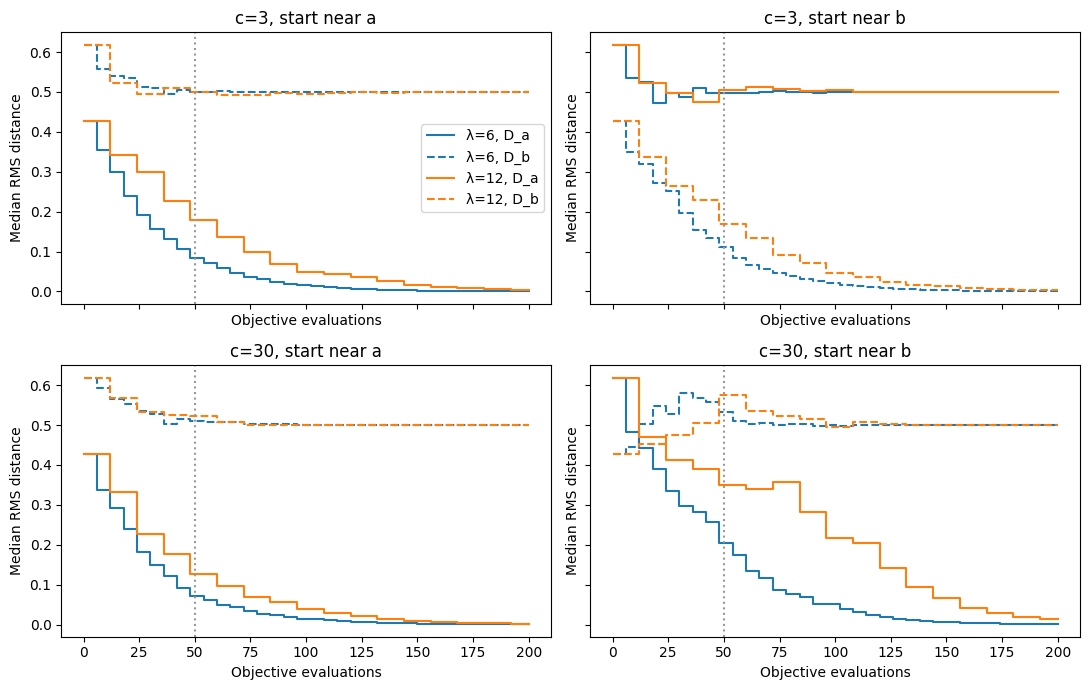

In [ ]:
# Compare states on a common evaluation grid. Between completed updates,
# carry forward the latest available sampling distribution.
run_keys = ["c", "start_basin", "start_fraction", "seed", "popsize"]
grid = pd.RangeIndex(201, name="evaluations")

curves = (
    history.set_index("evaluations")
    .groupby(run_keys)[["D_a", "D_b"]]
    .apply(lambda run: run.reindex(grid).ffill())
    .reset_index()
    .groupby(["c", "start_basin", "popsize", "evaluations"])[["D_a", "D_b"]]
    .median()
    .reset_index()
)

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, sharey=True)

for i, c in enumerate(c_values):
    for j, basin in enumerate(("a", "b")):
        ax = axes[i, j]
        panel = curves[(curves["c"] == c) & (curves["start_basin"] == basin)]

        for popsize, group in panel.groupby("popsize"):
            color = "tab:blue" if popsize == baseline_popsize else "tab:orange"
            for metric, style in (("D_a", "-"), ("D_b", "--")):
                ax.step(
                    group["evaluations"], group[metric],
                    where="post", color=color, linestyle=style,
                    label=f"λ={popsize}, {metric}",
                )

        ax.axvline(50, color="0.6", linestyle=":")
        ax.set_title(f"c={c}, start near {basin}")
        ax.set_xlabel("Objective evaluations")
        ax.set_ylabel("Median RMS distance")

axes[0, 0].legend()
fig.tight_layout()
plt.show()

In [ ]:
run_keys = ["c", "start_basin", "start_fraction", "seed", "popsize"]
pair_keys = ["cutoff", "c", "start_basin", "start_fraction", "seed", "budget"]
budgets = tuple(B2_SETTINGS["budgets"])
cutoffs = tuple(B2_SETTINGS["analysis"]["settling_cutoffs"])  # Main cutoff and a stricter sensitivity check.

rows = []

for keys, run in history.groupby(run_keys, sort=True):
    run = run.sort_values("evaluations")
    run_info = dict(zip(run_keys, keys))

    for budget in budgets:
        path = run.loc[run["evaluations"] <= budget]
        end = path.iloc[-1]
        assert end["evaluations"] == budget, (keys, budget)

        for cutoff in cutoffs:
            final_basin = "neither"
            settling_eval = np.nan

            if end["D_a"] <= cutoff:
                final_basin = "a"
            elif end["D_b"] <= cutoff:
                final_basin = "b"

            if final_basin != "neither":
                inside = path[f"D_{final_basin}"].le(cutoff).to_numpy()
                # Find the last recorded state outside the final neighbourhood.
                outside_indices = np.flatnonzero(~inside)
                entry_index = outside_indices[-1] + 1 if outside_indices.size else 0
                settling_eval = int(path.iloc[entry_index]["last_update"])

            rows.append({
                **run_info,
                "budget": budget,
                "cutoff": cutoff,
                "final_basin": final_basin,
                "settling_eval": settling_eval,
                "last_update": end["last_update"],
                "D_a": end["D_a"],
                "D_b": end["D_b"],
                "mean_dist_a": end["mean_dist_a"],
                "mean_dist_b": end["mean_dist_b"],
                "spread": end["spread"],
                "best_f": end["best_f"],
                "first_hit": end["first_hit"],
                "hit": pd.notna(end["first_hit"]),
            })

run_details = pd.DataFrame(rows)

metrics = [
    "final_basin", "settling_eval", "last_update", "D_a", "D_b",
    "mean_dist_a", "mean_dist_b", "spread", "best_f", "first_hit", "hit",
]

pairs = run_details.pivot(index=pair_keys, columns="popsize", values=metrics)
pairs.columns = [f"{metric}_{popsize}" for metric, popsize in pairs.columns]
pairs = pairs.reset_index()

assert pairs[["final_basin_6", "final_basin_12"]].notna().all().all()

pairs["settling_gap"] = (
    pd.to_numeric(pairs["settling_eval_12"])
    - pd.to_numeric(pairs["settling_eval_6"])
)

In [ ]:
group_keys = ["cutoff", "c", "start_basin", "budget"]
basins = ["a", "b", "neither"]

# Q1. Where did each population finish? Keep all nine outcomes, including zeros.
destination_rows = []
discovery_rows = []

for keys, group in pairs.groupby(group_keys, sort=True):
    info = dict(zip(group_keys, keys))

    for basin_6 in basins:
        for basin_12 in basins:
            matched = (
                group["final_basin_6"].eq(basin_6)
                & group["final_basin_12"].eq(basin_12)
            )
            destination_rows.append({
                **info,
                "population_6_finished": basin_6,
                "population_12_finished": basin_12,
                "pairs": int(matched.sum()),
            })

    for popsize in (6, 12):
        hit = group[f"hit_{popsize}"].eq(True)
        near_a = group[f"final_basin_{popsize}"].eq("a")
        near_b = group[f"final_basin_{popsize}"].eq("b")
        discovery_rows.append({
            **info,
            "popsize": popsize,
            "runs": len(group),
            "hit_f_below_1": int(hit.sum()),
            "finished_near_a": int(near_a.sum()),
            "finished_near_b": int(near_b.sum()),
            "hit_but_finished_near_a": int((hit & near_a).sum()),
        })

destination = pd.DataFrame(destination_rows)
discovery = pd.DataFrame(discovery_rows)

# Q2. Compare speed only for pairs that finished near the same minimum.
same_basin = pairs.loc[
    pairs["final_basin_6"].eq(pairs["final_basin_12"])
    & pairs["final_basin_6"].isin(["a", "b"])
].copy()

speed = (
    same_basin.groupby(group_keys + ["final_basin_6"])["settling_gap"]
    .agg(
        pairs="size",
        pop6_earlier=lambda gap: (gap > 0).sum(),
        tied=lambda gap: (gap == 0).sum(),
        pop12_earlier=lambda gap: (gap < 0).sum(),
        median_evals_saved_by_pop6="median",
    )
    .rename_axis(index=group_keys + ["shared_final_basin"])
    .reset_index()
)

# Start with the most interesting case. Remove this filter to see all settings.
focus = "cutoff == 0.05 and c == 30 and start_basin == 'b' and budget == 200"

display(
    destination.query(focus).pivot(
        index="population_6_finished",
        columns="population_12_finished",
        values="pairs",
    )
)
display(speed.query(focus))
display(discovery.query(focus))

# Exact seed IDs and values for pairs that finished in different basins.
display(
    pairs.query(focus)
    .loc[lambda df: df["final_basin_6"].ne(df["final_basin_12"])]
    [[
        "start_fraction", "seed", "final_basin_6", "final_basin_12",
        "settling_eval_6", "settling_eval_12",
        "first_hit_6", "first_hit_12", "best_f_6", "best_f_12",
    ]]
    .sort_values(["start_fraction", "seed"])
)

population_12_finished,a,b,neither
population_6_finished,,,
a,24,8,9
b,7,4,0
neither,2,2,4


,cutoff,c,start_basin,budget,shared_final_basin,pairs,pop6_earlier,tied,pop12_earlier,median_evals_saved_by_pop6
10,0.05,30,b,200,a,24,21,2,1,51.0
11,0.05,30,b,200,b,4,4,0,0,60.0


,cutoff,c,start_basin,budget,popsize,runs,hit_f_below_1,finished_near_a,finished_near_b,hit_but_finished_near_a
30,0.05,30,b,200,6,60,23,41,11,9
31,0.05,30,b,200,12,60,44,33,14,22


,start_fraction,seed,final_basin_6,final_basin_12,settling_eval_6,settling_eval_12,first_hit_6,first_hit_12,best_f_6,best_f_12
841,0.05,1,b,a,48.0,120.0,14.0,23.0,0.0,0.65478
849,0.05,5,a,neither,60.0,NaN,NaN,64.0,1.0,0.010271
851,0.05,6,a,b,90.0,132.0,NaN,8.0,1.000008,0.000101
855,0.05,8,a,b,90.0,156.0,NaN,10.0,1.000001,0.000027
859,0.05,10,a,b,84.0,96.0,4.0,4.0,0.21159,0.000009
861,0.05,11,a,neither,126.0,NaN,10.0,16.0,0.178552,0.581139
877,0.05,19,b,a,54.0,132.0,7.0,29.0,0.0,0.15015
881,0.10,1,b,a,48.0,156.0,7.0,59.0,0.0,0.377799
895,0.10,8,neither,b,NaN,168.0,NaN,15.0,1.000097,0.00008
899,0.10,10,a,b,84.0,96.0,4.0,4.0,0.124149,0.000002


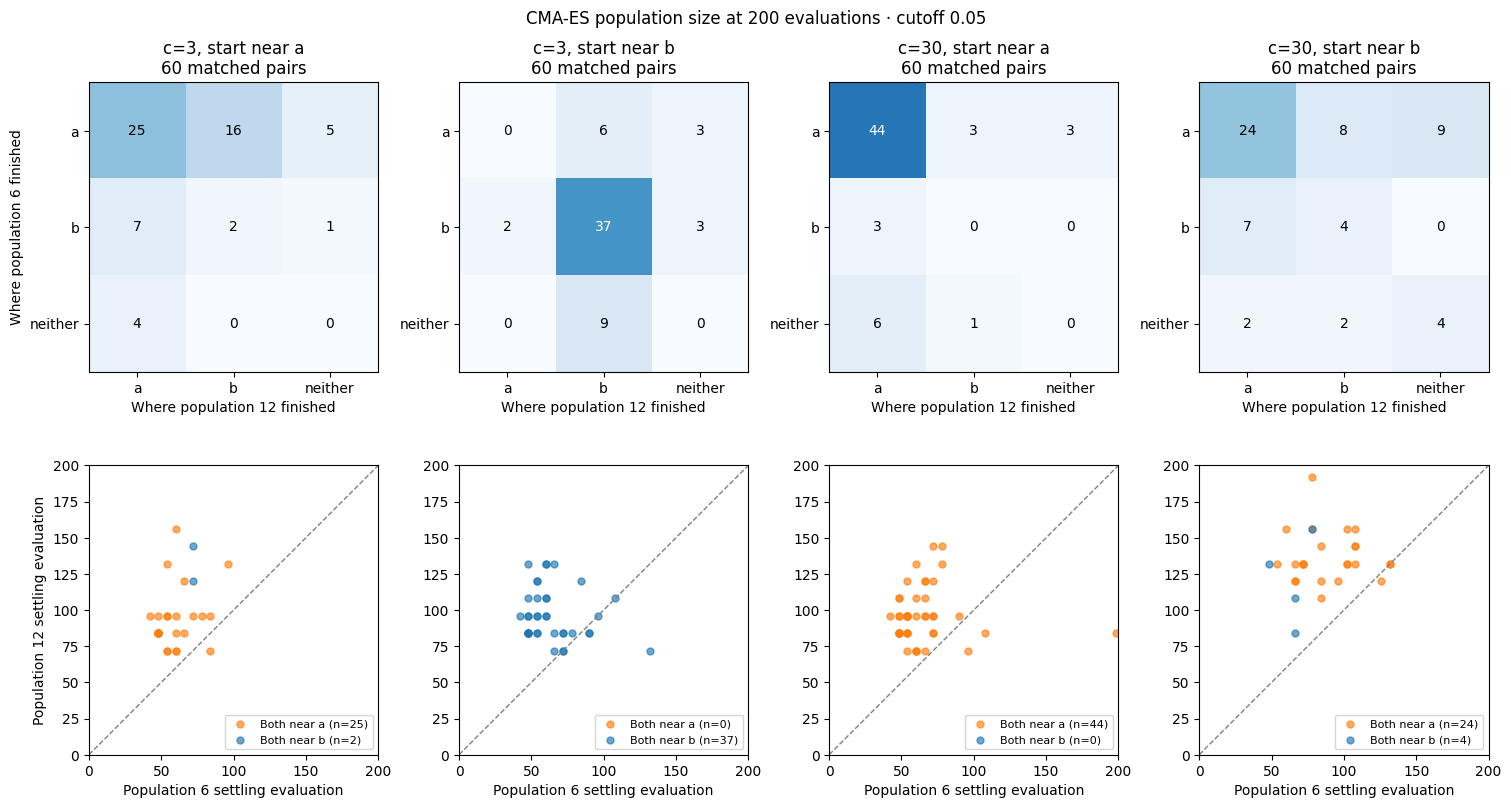

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
budget = 200  # Change to 50 to see the earlier checkpoint.
cutoff = 0.05
settings = [(3, "a"), (3, "b"), (30, "a"), (30, "b")]
basins = ["a", "b", "neither"]
colors = {"a": "tab:orange", "b": "tab:blue"}

data = pairs.loc[
    pairs["budget"].eq(budget) & np.isclose(pairs["cutoff"], cutoff)
]

fig, axes = plt.subplots(2, 4, figsize=(15, 8), layout="constrained")

for col, (c, start) in enumerate(settings):
    group = data.loc[data["c"].eq(c) & data["start_basin"].eq(start)]

    # Top row: exact counts of the two populations' final outcomes.
    counts = pd.crosstab(group["final_basin_6"], group["final_basin_12"])
    counts = counts.reindex(index=basins, columns=basins, fill_value=0)

    ax = axes[0, col]
    ax.imshow(counts.to_numpy(), cmap="Blues", vmin=0, vmax=len(group))
    ax.set_xticks(range(3), basins)
    ax.set_yticks(range(3), basins)
    ax.set_xlabel("Where population 12 finished")
    if col == 0:
        ax.set_ylabel("Where population 6 finished")
    ax.set_title(f"c={c}, start near {start}\n{len(group)} matched pairs")

    for i in range(3):
        for j in range(3):
            count = counts.iloc[i, j]
            ax.text(
                j, i, str(count), ha="center", va="center",
                color="white" if count > len(group) / 2 else "black",
            )

    # Bottom row: settling time for pairs with a shared final minimum.
    ax = axes[1, col]
    ax.plot([0, budget], [0, budget], "--", color="0.5", linewidth=1)

    for basin in ("a", "b"):
        same_basin = group.loc[
            group["final_basin_6"].eq(basin)
            & group["final_basin_12"].eq(basin)
        ]
        ax.scatter(
            pd.to_numeric(same_basin["settling_eval_6"]),
            pd.to_numeric(same_basin["settling_eval_12"]),
            color=colors[basin], alpha=0.65, s=25,
            label=f"Both near {basin} (n={len(same_basin)})",
        )

    ax.set(xlim=(0, budget), ylim=(0, budget), aspect="equal")
    ax.set_xlabel("Population 6 settling evaluation")
    if col == 0:
        ax.set_ylabel("Population 12 settling evaluation")
    ax.legend(loc="lower right", fontsize=8)

fig.suptitle(f"CMA-ES population size at {budget} evaluations · cutoff {cutoff}")

result_dir = RESULTS_DIR
output = result_dir / f"experiment1_population_comparison_{budget}.png"

fig.savefig(output, dpi=200, bbox_inches="tight")
plt.show()

print(f"Saved to {output}")

In [ ]:
# fixed mu/lambda change the other

In [ ]:
# Existing notebook variables: a, b, r0, lower, upper, two_basin_function.
experiment_configs = list(product(B2_SETTINGS["factorial_populations"], B2_SETTINGS["factorial_parents"]))
experiment_budgets = tuple(B2_SETTINGS["budgets"])
experiment_c_values = tuple(B2_SETTINGS["penalties"])
experiment_seeds = B2_SETTINGS["seeds"]
experiment_fractions = tuple(B2_SETTINGS["start_fractions"])
experiment_sigma0 = B2_SETTINGS["sigma0"]

domain_lower = np.asarray(lower, dtype=float)
domain_width = np.asarray(upper, dtype=float) - domain_lower
a_unit = (np.asarray(a) - domain_lower) / domain_width
b_unit = (np.asarray(b) - domain_lower) / domain_width

experiment_starts = [
    (basin, fraction, centre + fraction * (other - centre))
    for basin, centre, other in (
        ("a", a_unit, b_unit),
        ("b", b_unit, a_unit),
    )
    for fraction in experiment_fractions
]


def make_cma_strategy(x0, seed, popsize, mu):
    es = cma.CMAEvolutionStrategy(
        x0,
        experiment_sigma0,
        {
            "bounds": [0.0, 1.0],
            "seed": seed,
            "popsize": popsize,
            "CMA_mu": mu,
            "verbose": -9,
            "verb_log": 0,
        },
    )
    actual = (es.popsize, es.sp.weights.mu)
    if actual != (popsize, mu):
        raise ValueError(f"Requested {(popsize, mu)}, but pycma used {actual}")
    return es


for popsize, mu in experiment_configs:
    probe = make_cma_strategy(experiment_starts[0][2], 1, popsize, mu)
    print(
        f"λ={probe.popsize}, μ={probe.sp.weights.mu}, "
        f"mean weights={np.round(probe.sp.weights[:mu], 4)}"
    )


def run_cma_configuration(c_value, basin, fraction, x0, seed, popsize, mu):
    es = make_cma_strategy(x0, seed, popsize, mu)
    evaluations = 0
    last_update = 0
    best_f = np.inf
    first_hit = None
    records = []

    def record_state():
        mean = np.asarray(es.mean)
        scaling = np.broadcast_to(np.asarray(es.sigma_vec.scaling), mean.shape)
        variance = es.sigma**2 * np.dot(np.diag(es.C), scaling**2)
        mean_dist_a = np.linalg.norm(mean - a_unit)
        mean_dist_b = np.linalg.norm(mean - b_unit)

        records.append({
            "c": c_value,
            "start_basin": basin,
            "start_fraction": fraction,
            "seed": seed,
            "popsize": popsize,
            "mu": mu,
            "evaluations": evaluations,
            "last_update": last_update,
            "checkpoint": evaluations in experiment_budgets,
            "D_a": np.sqrt(mean_dist_a**2 + variance),
            "D_b": np.sqrt(mean_dist_b**2 + variance),
            "mean_dist_a": mean_dist_a,
            "mean_dist_b": mean_dist_b,
            "spread": np.sqrt(variance),
            "best_f": best_f,
            "first_hit": first_hit,
        })

    record_state()
    max_budget = max(experiment_budgets)

    while evaluations < max_budget:
        candidates = es.ask()
        values = []

        for candidate in candidates:
            x = domain_lower + domain_width * np.asarray(candidate)
            value = float(two_basin_function(x, c_value, a, b, r0))
            values.append(value)
            evaluations += 1
            best_f = min(best_f, value)

            if first_hit is None and value < 1.0:
                first_hit = evaluations

            completed_generation = len(values) == len(candidates)
            if completed_generation:
                es.tell(candidates, values)
                last_update = evaluations

            if completed_generation or evaluations in experiment_budgets:
                record_state()

            if evaluations == max_budget:
                break

    return records


factorial_rows = []

for popsize, mu in experiment_configs:
    for c_value in experiment_c_values:
        for basin, fraction, x0 in experiment_starts:
            for seed in experiment_seeds:
                factorial_rows.extend(
                    run_cma_configuration(
                        c_value, basin, fraction, x0, seed, popsize, mu
                    )
                )
    print(f"Finished λ={popsize}, μ={mu}")

factorial_history = pd.DataFrame(factorial_rows)

λ=6, μ=3, mean weights=[0.637  0.2846 0.0784]
λ=6, μ=6, mean weights=[0.4024 0.2534 0.1662 0.1044 0.0564 0.0172]
λ=12, μ=3, mean weights=[0.637  0.2846 0.0784]
λ=12, μ=6, mean weights=[0.4024 0.2534 0.1662 0.1044 0.0564 0.0172]
Finished λ=6, μ=3
Finished λ=6, μ=6
Finished λ=12, μ=3
Finished λ=12, μ=6


In [ ]:
settling_cutoff = B2_SETTINGS["analysis"]["settling_cutoff"]
factorial_results = factorial_history.loc[factorial_history["checkpoint"]].copy()

factorial_results["near_a"] = factorial_results["D_a"].le(settling_cutoff)
factorial_results["near_b"] = factorial_results["D_b"].le(settling_cutoff)
factorial_results["neither"] = ~(
    factorial_results["near_a"] | factorial_results["near_b"]
)
factorial_results["hit"] = factorial_results["first_hit"].notna()
factorial_results["hit_but_near_a"] = (
    factorial_results["hit"] & factorial_results["near_a"]
)

factorial_summary = (
    factorial_results.groupby(["c", "start_basin", "evaluations", "popsize", "mu"])
    .agg(
        runs=("seed", "size"),
        near_a=("near_a", "sum"),
        near_b=("near_b", "sum"),
        neither=("neither", "sum"),
        hits=("hit", "sum"),
        hit_but_near_a=("hit_but_near_a", "sum"),
        median_best_f=("best_f", "median"),
        median_spread=("spread", "median"),
    )
    .reset_index()
)
factorial_summary["near_b_pct"] = (
    100 * factorial_summary["near_b"] / factorial_summary["runs"]
)

display(factorial_summary.round(5))

near_b_rates = factorial_summary.pivot(
    index=["c", "start_basin", "evaluations"],
    columns=["popsize", "mu"],
    values="near_b_pct",
)

factorial_effects = pd.DataFrame({
    "mu 3 to 6 | lambda 6": near_b_rates[(6, 6)] - near_b_rates[(6, 3)],
    "mu 3 to 6 | lambda 12": near_b_rates[(12, 6)] - near_b_rates[(12, 3)],
    "lambda 6 to 12 | mu 3": near_b_rates[(12, 3)] - near_b_rates[(6, 3)],
    "lambda 6 to 12 | mu 6": near_b_rates[(12, 6)] - near_b_rates[(6, 6)],
})

print("Change in runs near b, in percentage points")
display(factorial_effects.round(1))

,c,start_basin,evaluations,popsize,mu,runs,near_a,near_b,neither,hits,hit_but_near_a,median_best_f,median_spread,near_b_pct
0,3,a,50,6,3,60,9,0,51,17,0,1.00822,0.07388,0.00000
1,3,a,50,6,6,60,7,0,53,19,0,1.00596,0.08458,0.00000
2,3,a,50,12,3,60,0,0,60,29,0,1.00286,0.17588,0.00000
3,3,a,50,12,6,60,0,0,60,25,0,1.00692,0.15146,0.00000
4,3,a,200,6,3,60,46,10,4,17,7,1.00000,0.00022,16.66667
5,3,a,200,6,6,60,51,6,3,19,13,1.00000,0.00076,10.00000
6,3,a,200,12,3,60,35,19,6,30,5,0.76762,0.00398,31.66667
7,3,a,200,12,6,60,36,18,6,27,3,1.00000,0.00367,30.00000
8,3,b,50,6,3,60,0,10,50,48,0,0.03903,0.08237,16.66667
9,3,b,50,6,6,60,0,6,54,56,0,0.06477,0.11586,10.00000


Change in runs near b, in percentage points


mu 3 to 6 | lambda 6  mu 3 to 6 | lambda 12  \
c  start_basin evaluations                                                
3  a           50                            0.0                    0.0   
               200                          -6.7                   -1.7   
   b           50                           -6.7                    0.0   
               200                           1.7                    1.7   
30 a           50                            0.0                    0.0   
               200                          -5.0                   -6.7   
   b           50                           -6.7                    0.0   
               200                          -5.0                   -5.0   

                            lambda 6 to 12 | mu 3  lambda 6 to 12 | mu 6  
c  start_basin evaluations                                                
3  a           50                             0.0                    0.0  
               200                           15.0                   20.0  
   b           50                           -16.7                  -10.0  
               200                           15.0                   15.0  
30 a           50                             0.0                    0.0  
               200                            8.3                    6.7  
   b           50                            -6.7                    0.0  
               200                           10.0                   10.0

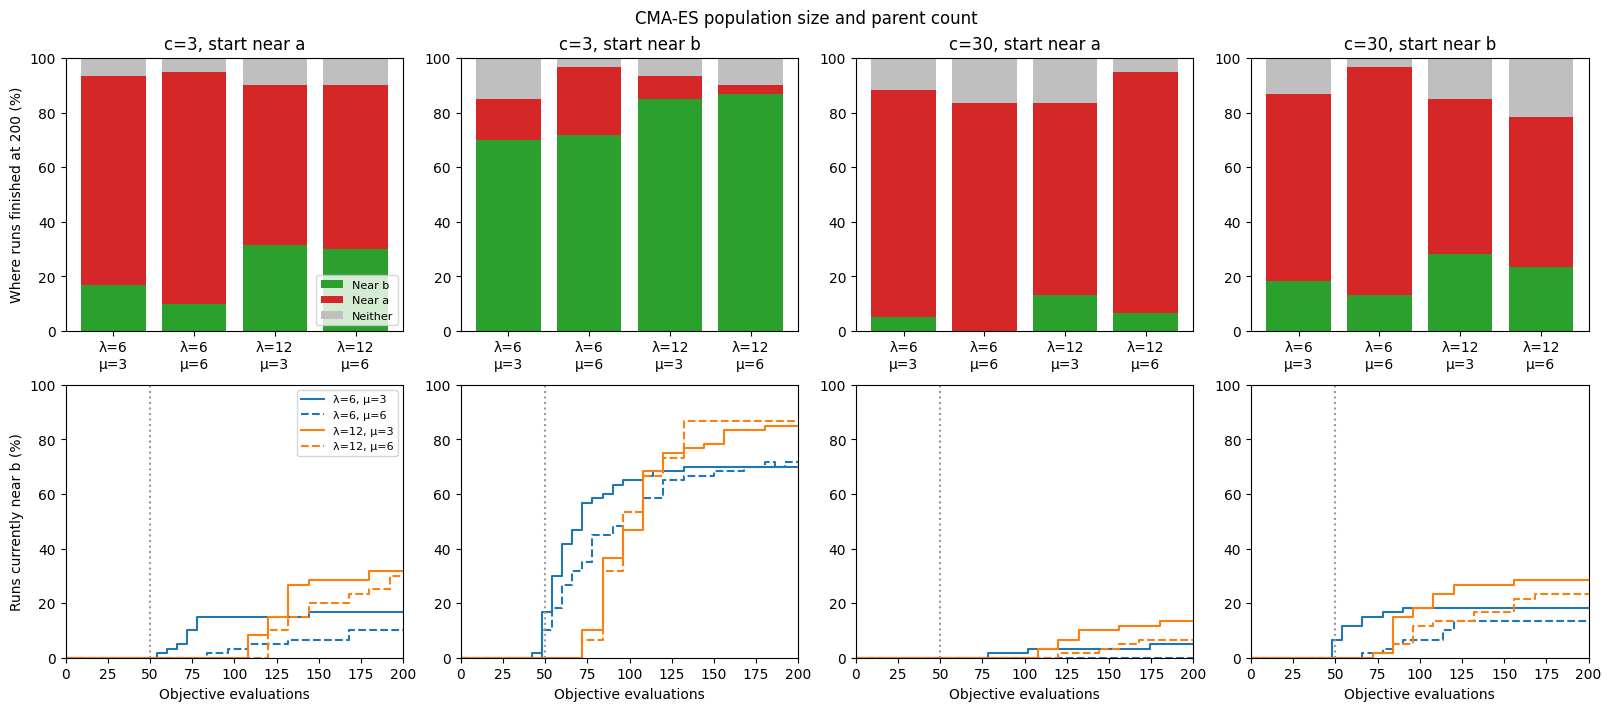

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
run_keys = ["c", "start_basin", "start_fraction", "seed", "popsize", "mu"]
evaluation_grid = pd.RangeIndex(201, name="evaluations")

# Carry forward the latest distribution between completed updates.
progress_runs = []

for key, run in factorial_history.groupby(run_keys):
    distances = run.set_index("evaluations")["D_b"].reindex(evaluation_grid).ffill()
    progress_runs.append(
        distances.le(settling_cutoff)
        .rename("near_b")
        .reset_index()
        .assign(**dict(zip(run_keys, key)))
    )

factorial_progress = (
    pd.concat(progress_runs, ignore_index=True)
    .groupby(["c", "start_basin", "popsize", "mu", "evaluations"])["near_b"]
    .mean()
    .mul(100)
    .rename("near_b_pct")
    .reset_index()
)

panels = [(3, "a"), (3, "b"), (30, "a"), (30, "b")]
config_index = pd.MultiIndex.from_tuples(experiment_configs, names=["popsize", "mu"])
population_colors = {6: "tab:blue", 12: "tab:orange"}
parent_styles = {3: "-", 6: "--"}
positions = np.arange(len(experiment_configs))

fig, axes = plt.subplots(2, 4, figsize=(16, 7), layout="constrained")

for col, (c_value, basin) in enumerate(panels):
    final = (
        factorial_summary.query(
            "c == @c_value and start_basin == @basin and evaluations == 200"
        )
        .set_index(["popsize", "mu"])
        .reindex(config_index)
    )

    ax = axes[0, col]
    bottom = np.zeros(len(experiment_configs))

    for metric, label, color in (
        ("near_b", "Near b", "tab:green"),
        ("near_a", "Near a", "tab:red"),
        ("neither", "Neither", "0.75"),
    ):
        height = 100 * final[metric].to_numpy() / final["runs"].to_numpy()
        ax.bar(positions, height, bottom=bottom, color=color, label=label)
        bottom += height

    ax.set_xticks(positions, [f"λ={p}\nμ={m}" for p, m in experiment_configs])
    ax.set_ylim(0, 100)
    ax.set_title(f"c={c_value}, start near {basin}")
    if col == 0:
        ax.set_ylabel("Where runs finished at 200 (%)")
        ax.legend(fontsize=8)

    ax = axes[1, col]
    panel = factorial_progress.query("c == @c_value and start_basin == @basin")

    for (popsize, mu), curve in panel.groupby(["popsize", "mu"]):
        ax.step(
            curve["evaluations"],
            curve["near_b_pct"],
            where="post",
            color=population_colors[popsize],
            linestyle=parent_styles[mu],
            label=f"λ={popsize}, μ={mu}",
        )

    ax.axvline(50, color="0.6", linestyle=":")
    ax.set(xlim=(0, 200), ylim=(0, 100), xlabel="Objective evaluations")
    if col == 0:
        ax.set_ylabel("Runs currently near b (%)")
        ax.legend(fontsize=8)

fig.suptitle("CMA-ES population size and parent count")

output_dir = RESULTS_DIR

plot_path = output_dir / "cmaes_lambda_mu_comparison.png"
zip_path = output_dir / "cmaes_lambda_mu_results.zip"

fig.savefig(plot_path, dpi=200, bbox_inches="tight")
plt.show()

with ZipFile(zip_path, "w") as archive:
    archive.write(plot_path, arcname=plot_path.name)
    archive.writestr("summary.csv", factorial_summary.to_csv(index=False))
    archive.writestr("effects.csv", factorial_effects.to_csv())
    archive.writestr("checkpoint_results.csv", factorial_results.to_csv(index=False))
    archive.writestr("full_history.csv", factorial_history.to_csv(index=False))

print(f"Saved to {zip_path}")

Reused λ=6, μ=3
Finished λ=8, μ=4
Reused λ=12, μ=6
Finished λ=16, μ=8
Finished λ=24, μ=12
Finished λ=32, μ=16
Finished λ=48, μ=24
Finished λ=12, μ=2
Finished λ=12, μ=4
Finished λ=12, μ=8
Finished λ=12, μ=10


,sweep,c,start_basin,popsize,mu,refinements,runs,median_best_f
0,Population sweep,3,a,12,6,21,60,1.000000
1,Population sweep,3,b,12,6,56,60,0.000019
2,Population sweep,30,a,32,16,8,60,1.000155
3,Population sweep,30,b,16,8,22,60,0.048516
4,Population sweep,30,b,32,16,22,60,0.017748
5,Parent-count sweep,3,a,12,4,27,60,1.000001
6,Parent-count sweep,3,b,12,6,56,60,0.000019
7,Parent-count sweep,30,a,12,4,11,60,1.000007
8,Parent-count sweep,30,b,12,2,28,60,0.043554


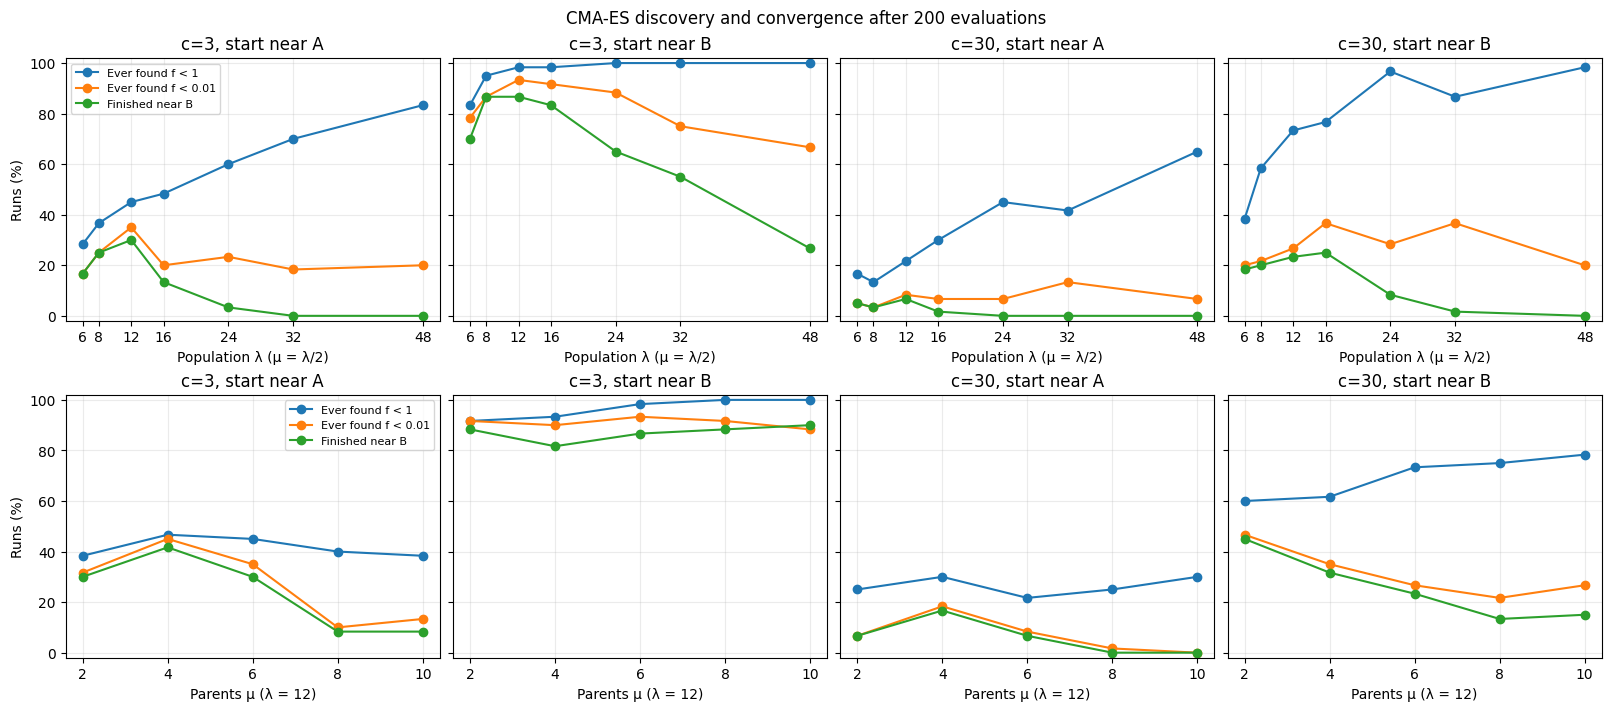

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
lambda_values = B2_SETTINGS["population_sweep"]
mu_values = B2_SETTINGS["parent_sweep"]

lambda_configs = [(lam, lam // 2) for lam in lambda_values]
mu_configs = [(B2_SETTINGS["parent_sweep_population"], mu) for mu in mu_values]
sweep_configs = list(dict.fromkeys(lambda_configs + mu_configs))

histories = []

for lam, mu in sweep_configs:
    existing = factorial_history.loc[
        factorial_history["popsize"].eq(lam) & factorial_history["mu"].eq(mu)
    ]

    if not existing.empty:
        histories.append(existing)
        print(f"Reused λ={lam}, μ={mu}")
        continue

    rows = [
        row
        for c_value in experiment_c_values
        for basin, fraction, x0 in experiment_starts
        for seed in experiment_seeds
        for row in run_cma_configuration(
            c_value, basin, fraction, x0, seed, lam, mu
        )
    ]
    histories.append(pd.DataFrame(rows))
    print(f"Finished λ={lam}, μ={mu}")

sweep_history = pd.concat(histories, ignore_index=True)

checkpoints = sweep_history.loc[sweep_history["checkpoint"]].copy()
checkpoints["discovered"] = checkpoints["best_f"].lt(1.0)
checkpoints["refined"] = checkpoints["best_f"].lt(0.01)
checkpoints["near_b"] = checkpoints["D_b"].le(B2_SETTINGS["analysis"]["settling_cutoff"])

sweep_summary = (
    checkpoints.groupby(
        ["c", "start_basin", "evaluations", "popsize", "mu"], as_index=False
    )
    .agg(
        runs=("seed", "size"),
        discoveries=("discovered", "sum"),
        refinements=("refined", "sum"),
        finished_near_b=("near_b", "sum"),
        median_best_f=("best_f", "median"),
    )
)

for count in ("discoveries", "refinements", "finished_near_b"):
    sweep_summary[f"{count}_pct"] = 100 * sweep_summary[count] / sweep_summary["runs"]

final = sweep_summary.loc[sweep_summary["evaluations"].eq(200)]
lambda_sweep = final.loc[final["mu"].eq(final["popsize"] // 2)]
mu_sweep = final.loc[final["popsize"].eq(12) & final["mu"].isin(mu_values)]

# Report all ties for the best observed refinement rate.
best_settings = []
for label, table in (
    ("Population sweep", lambda_sweep),
    ("Parent-count sweep", mu_sweep),
):
    best_rate = table.groupby(["c", "start_basin"])["refinements_pct"].transform("max")
    best_settings.append(
        table.loc[table["refinements_pct"].eq(best_rate)].assign(sweep=label)
    )

best_settings = pd.concat(best_settings, ignore_index=True)
display(best_settings[[
    "sweep", "c", "start_basin", "popsize", "mu",
    "refinements", "runs", "median_best_f",
]])

# Each panel separates finding B, refining a point, and finishing near B.
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharey=True, layout="constrained")
conditions = [(3, "a"), (3, "b"), (30, "a"), (30, "b")]
metrics = [
    ("discoveries_pct", "Ever found f < 1"),
    ("refinements_pct", "Ever found f < 0.01"),
    ("finished_near_b_pct", "Finished near B"),
]

for row, (table, x_key, ticks, label) in enumerate([
    (lambda_sweep, "popsize", lambda_values, "Population λ (μ = λ/2)"),
    (mu_sweep, "mu", mu_values, "Parents μ (λ = 12)"),
]):
    for col, (c_value, basin) in enumerate(conditions):
        ax = axes[row, col]
        panel = table.loc[
            table["c"].eq(c_value) & table["start_basin"].eq(basin)
        ].sort_values(x_key)

        for metric, legend in metrics:
            ax.plot(panel[x_key], panel[metric], marker="o", label=legend)

        ax.set_title(f"c={c_value}, start near {basin.upper()}")
        ax.set(xlabel=label, xticks=ticks, ylim=(-2, 102))
        ax.grid(alpha=0.25)
        if col == 0:
            ax.set_ylabel("Runs (%)")
            ax.legend(fontsize=8)

fig.suptitle("CMA-ES discovery and convergence after 200 evaluations")

output_dir = RESULTS_DIR

plot_path = output_dir / "cmaes_convergence_sweeps.png"
zip_path = output_dir / "cmaes_convergence_sweeps.zip"
fig.savefig(plot_path, dpi=200, bbox_inches="tight")
plt.show()

with ZipFile(zip_path, "w") as archive:
    archive.write(plot_path, arcname=plot_path.name)
    archive.writestr("summary.csv", sweep_summary.to_csv(index=False))
    archive.writestr("best_settings.csv", best_settings.to_csv(index=False))
    archive.writestr("checkpoint_results.csv", checkpoints.to_csv(index=False))
    archive.writestr("full_history.csv", sweep_history.to_csv(index=False))

print(f"Saved to {zip_path}")

In [ ]:
# try make domain larger to see whether f < 1 still holds

## 1. Setup

In [ ]:
LOWER = np.full(2, B2_SETTINGS["wide_domain"]["lower"])
UPPER = np.full(2, B2_SETTINGS["wide_domain"]["upper"])
WIDTH = UPPER - LOWER

A = np.asarray(B2_SETTINGS["wide_domain"]["a"])
B = np.asarray(B2_SETTINGS["wide_domain"]["b"])
R0 = B2_SETTINGS["wide_domain"]["r0"]

A_UNIT = (A - LOWER) / WIDTH
B_UNIT = (B - LOWER) / WIDTH

SIGMA0 = B2_SETTINGS["sigma0"]
C_VALUES = tuple(B2_SETTINGS["penalties"])
BUDGETS = tuple(B2_SETTINGS["budgets"])
SEEDS = B2_SETTINGS["seeds"]
START_FRACTIONS = tuple(B2_SETTINGS["start_fractions"])

LAMBDA_VALUES = tuple(B2_SETTINGS["population_sweep"])
MU_VALUES = tuple(B2_SETTINGS["parent_sweep"])
LAMBDA_CONFIGS = [(lam, lam // 2) for lam in LAMBDA_VALUES]
MU_CONFIGS = [(B2_SETTINGS["parent_sweep_population"], mu) for mu in MU_VALUES]
CONFIGS = list(dict.fromkeys(LAMBDA_CONFIGS + MU_CONFIGS))

# Same physical concentration cutoff as before.
# Original: 0.05 × 8 = 0.40. New: 0.01 × 40 = 0.40.
NEAR_B_CUTOFF = B2_SETTINGS["analysis"]["near_cutoff"] / WIDTH[0]

STARTS = [
    (basin, fraction, centre + fraction * (other - centre))
    for basin, centre, other in (
        ("a", A_UNIT, B_UNIT),
        ("b", B_UNIT, A_UNIT),
    )
    for fraction in START_FRACTIONS
]

display(pd.DataFrame([
    {
        "start_basin": basin,
        "fraction_toward_other_minimum": fraction,
        "start_x": (LOWER + WIDTH * x0)[0],
        "start_y": (LOWER + WIDTH * x0)[1],
    }
    for basin, fraction, x0 in STARTS
]))




assert objective(A, 30) == 1.0
assert objective(B, 30) == 0.0

,start_basin,fraction_toward_other_minimum,start_x,start_y
0,a,0.05,-9.0,0.0
1,a,0.10,-8.0,0.0
2,a,0.15,-7.0,0.0
3,b,0.05,9.0,0.0
4,b,0.10,8.0,0.0
5,b,0.15,7.0,0.0


In [ ]:
def make_strategy(x0, seed, lam, mu):
    es = cma.CMAEvolutionStrategy(
        x0.copy(),
        SIGMA0,
        {
            "bounds": [0.0, 1.0],
            "seed": int(seed),
            "popsize": lam,
            "CMA_mu": mu,
            "verbose": -9,
            "verb_log": 0,
        },
    )

    actual = (es.popsize, es.sp.weights.mu)
    if actual != (lam, mu):
        raise ValueError(f"Requested {(lam, mu)}, but pycma used {actual}")
    return es


def run_wide_cma(c_value, basin, fraction, x0, seed, lam, mu):
    es = make_strategy(x0, seed, lam, mu)
    max_budget = max(BUDGETS)

    evaluations = 0
    last_update = 0
    best_f = np.inf
    first_hit_eval = None
    first_hit_f = None
    first_hit_dist_b = None
    first_refined_eval = None
    records = []

    def record_state():
        mean = np.asarray(es.mean)
        scaling = np.broadcast_to(np.asarray(es.sigma_vec.scaling), mean.shape)
        variance = es.sigma**2 * np.dot(np.diag(es.C), scaling**2)
        mean_dist_a = np.linalg.norm(mean - A_UNIT)
        mean_dist_b = np.linalg.norm(mean - B_UNIT)

        records.append({
            "c": c_value,
            "start_basin": basin,
            "start_fraction": fraction,
            "seed": seed,
            "popsize": lam,
            "mu": mu,
            "evaluations": evaluations,
            "last_update": last_update,
            "checkpoint": evaluations in BUDGETS,
            "D_a": np.sqrt(mean_dist_a**2 + variance),
            "D_b": np.sqrt(mean_dist_b**2 + variance),
            "mean_dist_a": mean_dist_a,
            "mean_dist_b": mean_dist_b,
            "spread": np.sqrt(variance),
            "best_f": best_f,
            "first_hit_eval": first_hit_eval,
            "first_hit_f": first_hit_f,
            "first_hit_dist_b": first_hit_dist_b,
            "first_refined_eval": first_refined_eval,
        })

    record_state()

    while evaluations < max_budget:
        candidates = es.ask()
        values = []

        for candidate in candidates:
            x = LOWER + WIDTH * np.asarray(candidate)
            value = objective(x, c_value)
            values.append(value)
            evaluations += 1
            best_f = min(best_f, value)

            if first_hit_eval is None and value < 1.0:
                first_hit_eval = evaluations
                first_hit_f = value
                first_hit_dist_b = float(np.linalg.norm(x - B))

            if first_refined_eval is None and value < 0.01:
                first_refined_eval = evaluations

            completed_generation = len(values) == len(candidates)
            if completed_generation:
                es.tell(candidates, values)
                last_update = evaluations

            if completed_generation or evaluations in BUDGETS:
                record_state()

            if evaluations == max_budget:
                break

    return records


# Verify every configuration before running the sweep.
for lam, mu in CONFIGS:
    make_strategy(STARTS[0][2], 1, lam, mu)

wide_rows = []
for lam, mu in CONFIGS:
    for c_value in C_VALUES:
        for basin, fraction, x0 in STARTS:
            for seed in SEEDS:
                wide_rows.extend(
                    run_wide_cma(c_value, basin, fraction, x0, seed, lam, mu)
                )
    print(f"Finished λ={lam}, μ={mu}")

wide_history = pd.DataFrame(wide_rows)
wide_checkpoints = wide_history.loc[wide_history["checkpoint"]].copy()

expected_runs = len(CONFIGS) * len(C_VALUES) * len(STARTS) * len(SEEDS)
assert len(wide_checkpoints) == expected_runs * len(BUDGETS)
print(f"Completed {expected_runs:,} runs")

Finished λ=6, μ=3
Finished λ=8, μ=4
Finished λ=12, μ=6
Finished λ=16, μ=8
Finished λ=24, μ=12
Finished λ=32, μ=16
Finished λ=48, μ=24
Finished λ=12, μ=2
Finished λ=12, μ=4
Finished λ=12, μ=8
Finished λ=12, μ=10
Completed 2,640 runs


In [ ]:
wide_checkpoints["discovered"] = wide_checkpoints["best_f"].lt(1.0)
wide_checkpoints["refined"] = wide_checkpoints["best_f"].lt(0.01)
wide_checkpoints["near_b"] = wide_checkpoints["D_b"].le(NEAR_B_CUTOFF)

wide_summary = (
    wide_checkpoints.groupby(
        ["c", "start_basin", "evaluations", "popsize", "mu"],
        as_index=False,
    )
    .agg(
        runs=("seed", "size"),
        discoveries=("discovered", "sum"),
        refinements=("refined", "sum"),
        finished_near_b=("near_b", "sum"),
        median_best_f=("best_f", "median"),
    )
)

for metric in ("discoveries", "refinements", "finished_near_b"):
    wide_summary[f"{metric}_pct"] = 100 * wide_summary[metric] / wide_summary["runs"]


def split_sweeps(table):
    return [
        (
            table.loc[table["mu"].eq(table["popsize"] // 2)],
            "popsize", LAMBDA_VALUES, "Population λ (μ = λ/2)",
        ),
        (
            table.loc[table["popsize"].eq(12) & table["mu"].isin(MU_VALUES)],
            "mu", MU_VALUES, "Parents μ (λ = 12)",
        ),
    ]


wide_final = wide_summary.loc[wide_summary["evaluations"].eq(200)]

best_tables = []
for table, _, _, label in split_sweeps(wide_final):
    for metric in ("refinements", "finished_near_b"):
        peak = table.groupby(["c", "start_basin"])[metric].transform("max")
        best_tables.append(
            table.loc[table[metric].eq(peak)].assign(sweep=label, metric=metric)
        )

wide_best_settings = pd.concat(best_tables, ignore_index=True)

display(wide_best_settings[[
    "sweep", "metric", "c", "start_basin", "popsize", "mu",
    "discoveries", "refinements", "finished_near_b", "runs",
]])

,sweep,metric,c,start_basin,popsize,mu,discoveries,refinements,finished_near_b,runs
0,Population λ (μ = λ/2),refinements,3,a,12,6,4,2,1,60
1,Population λ (μ = λ/2),refinements,3,b,6,3,17,15,15,60
2,Population λ (μ = λ/2),refinements,30,a,6,3,1,0,0,60
3,Population λ (μ = λ/2),refinements,30,a,8,4,0,0,0,60
4,Population λ (μ = λ/2),refinements,30,a,12,6,0,0,0,60
5,Population λ (μ = λ/2),refinements,30,a,16,8,0,0,0,60
6,Population λ (μ = λ/2),refinements,30,a,24,12,2,0,0,60
7,Population λ (μ = λ/2),refinements,30,a,32,16,0,0,0,60
8,Population λ (μ = λ/2),refinements,30,a,48,24,1,0,0,60
9,Population λ (μ = λ/2),refinements,30,b,6,3,1,1,1,60


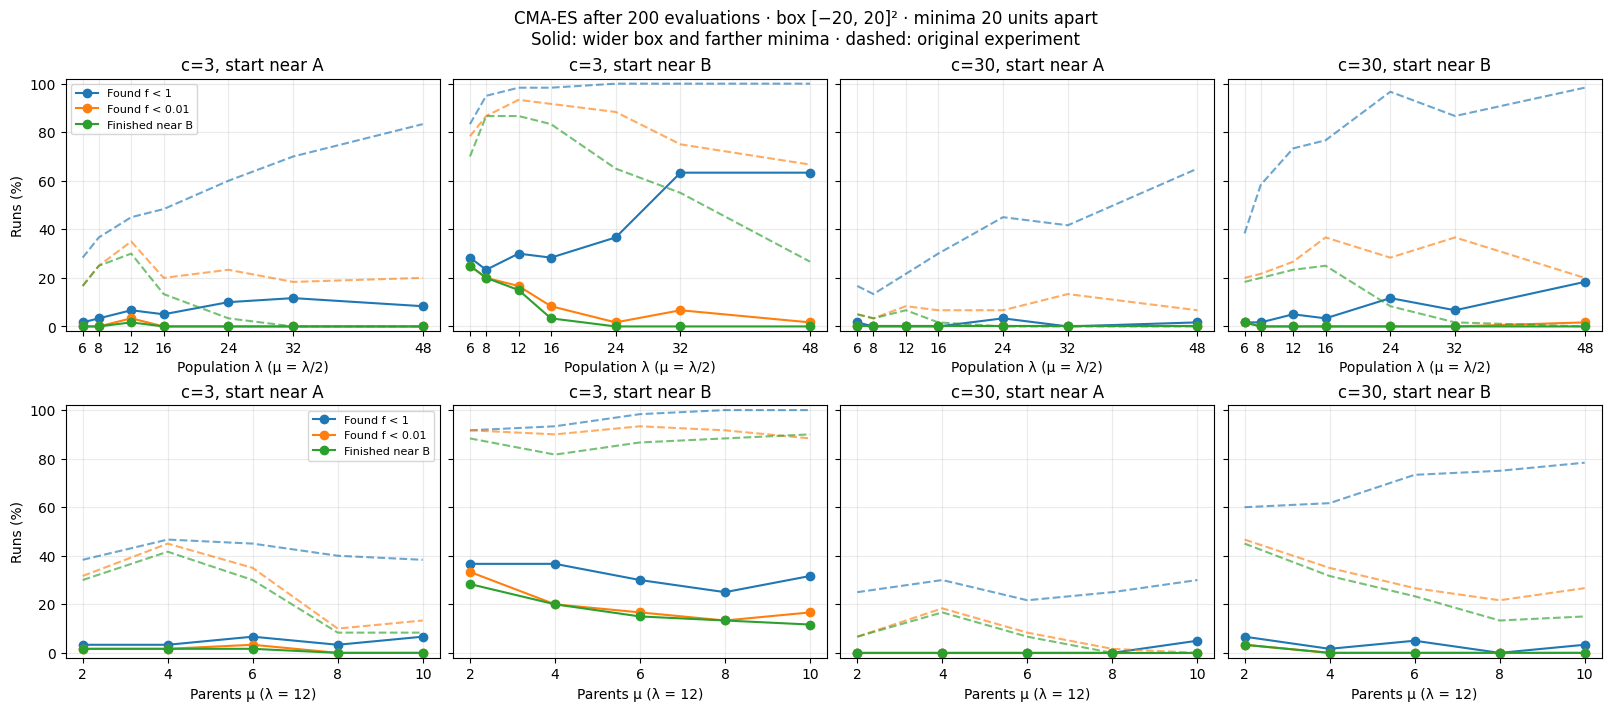

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Optional if the original sweep is no longer in memory:
# sweep_summary = pd.read_csv("summary(1).csv")

old_summary = globals().get("sweep_summary")
old_sweeps = None
if old_summary is not None:
    old_final = old_summary.loc[old_summary["evaluations"].eq(200)]
    old_sweeps = split_sweeps(old_final)

fig, axes = plt.subplots(
    2, 4, figsize=(16, 7), sharey=True, layout="constrained"
)

conditions = [(3, "a"), (3, "b"), (30, "a"), (30, "b")]
metrics = [
    ("discoveries_pct", "Found f < 1", "tab:blue"),
    ("refinements_pct", "Found f < 0.01", "tab:orange"),
    ("finished_near_b_pct", "Finished near B", "tab:green"),
]

for row, (table, x_key, ticks, xlabel) in enumerate(split_sweeps(wide_final)):
    for col, (c_value, basin) in enumerate(conditions):
        ax = axes[row, col]
        wide_panel = table.loc[
            table["c"].eq(c_value) & table["start_basin"].eq(basin)
        ].sort_values(x_key)

        for metric, label, color in metrics:
            ax.plot(
                wide_panel[x_key], wide_panel[metric],
                marker="o", color=color, label=label,
            )

            if old_sweeps is not None:
                old_table = old_sweeps[row][0]
                old_panel = old_table.loc[
                    old_table["c"].eq(c_value) & old_table["start_basin"].eq(basin)
                ].sort_values(x_key)
                ax.plot(
                    old_panel[x_key], old_panel[metric],
                    linestyle="--", color=color, alpha=0.65,
                )

        ax.set(
            title=f"c={c_value}, start near {basin.upper()}",
            xlabel=xlabel,
            xticks=ticks,
            ylim=(-2, 102),
        )
        ax.grid(alpha=0.25)

        if col == 0:
            ax.set_ylabel("Runs (%)")
            ax.legend(fontsize=8)

title = "CMA-ES after 200 evaluations · box [−20, 20]² · minima 20 units apart"
if old_sweeps is not None:
    title += "\nSolid: wider box and farther minima · dashed: original experiment"
fig.suptitle(title)

output_dir = RESULTS_DIR

plot_path = output_dir / "cmaes_wide_domain_farther_basins.png"
zip_path = output_dir / "cmaes_wide_domain_farther_basins.zip"

fig.savefig(plot_path, dpi=200, bbox_inches="tight")
plt.show()

with ZipFile(zip_path, "w", compression=ZIP_DEFLATED) as archive:
    archive.write(plot_path, arcname=plot_path.name)
    archive.writestr("summary.csv", wide_summary.to_csv(index=False))
    archive.writestr("best_settings.csv", wide_best_settings.to_csv(index=False))
    archive.writestr("checkpoint_results.csv", wide_checkpoints.to_csv(index=False))
    archive.writestr("full_history.csv", wide_history.to_csv(index=False))

print(f"Saved to {zip_path}")

In [ ]:
# try diff sigma0

In [ ]:
lam, mu = B2_SETTINGS["initial_spread"]["popsize"], B2_SETTINGS["initial_spread"]["mu"]
initial_sds = tuple(B2_SETTINGS["initial_spread"]["initial_sds"])
offsets = tuple(B2_SETTINGS["initial_spread"]["offsets"])

# Convert physical offsets to fractions along the line between A and B.
separation = np.linalg.norm(B - A)
sigma_starts = [
    (basin, offset, centre + (offset / separation) * (other - centre))
    for basin, centre, other in (
        ("a", A_UNIT, B_UNIT),
        ("b", B_UNIT, A_UNIT),
    )
    for offset in offsets
]

sigma_rows = []
original_sigma0 = SIGMA0

try:
    for initial_sd in initial_sds:
        SIGMA0 = initial_sd / WIDTH[0]

        for c_value in C_VALUES:
            for basin, offset, x0 in sigma_starts:
                for seed in SEEDS:
                    records = run_wide_cma(
                        c_value, basin, offset / separation, x0, seed, lam, mu
                    )
                    for record in records:
                        record["initial_sd"] = initial_sd
                        record["start_offset"] = offset
                    sigma_rows.extend(records)

        print(f"Finished initial SD={initial_sd:g} (SIGMA0={SIGMA0:g})")
finally:
    SIGMA0 = original_sigma0

sigma_history = pd.DataFrame(sigma_rows)
sigma_checkpoints = sigma_history.loc[sigma_history["checkpoint"]].copy()

sigma_checkpoints["first_generation_hit"] = (
    sigma_checkpoints["first_hit_eval"].le(lam)
)
sigma_checkpoints["discovered"] = sigma_checkpoints["best_f"].lt(1.0)
sigma_checkpoints["refined"] = sigma_checkpoints["best_f"].lt(0.01)
sigma_checkpoints["near_b"] = sigma_checkpoints["D_b"].le(NEAR_B_CUTOFF)

sigma_summary = (
    sigma_checkpoints
    .groupby(["c", "start_basin", "evaluations", "initial_sd"], as_index=False)
    .agg(
        runs=("seed", "size"),
        first_generation_hits=("first_generation_hit", "sum"),
        discoveries=("discovered", "sum"),
        refinements=("refined", "sum"),
        finished_near_b=("near_b", "sum"),
        median_best_f=("best_f", "median"),
    )
)

display(sigma_summary.round(5))

Finished initial SD=2.4 (SIGMA0=0.06)
Finished initial SD=12 (SIGMA0=0.3)


,c,start_basin,evaluations,initial_sd,runs,first_generation_hits,discoveries,refinements,finished_near_b,median_best_f
0,3,a,50,2.4,60,0,0,0,0,1.03713
1,3,a,50,12.0,60,0,0,0,0,2.56377
2,3,a,200,2.4,60,0,0,0,0,1.00001
3,3,a,200,12.0,60,0,1,0,0,1.00020
4,3,b,50,2.4,60,27,60,10,0,0.03699
5,3,b,50,12.0,60,0,1,0,0,2.74727
6,3,b,200,2.4,60,27,60,60,60,0.00001
7,3,b,200,12.0,60,0,16,9,9,1.00169
8,30,a,50,2.4,60,0,0,0,0,1.03713
9,30,a,50,12.0,60,0,0,0,0,1.93295


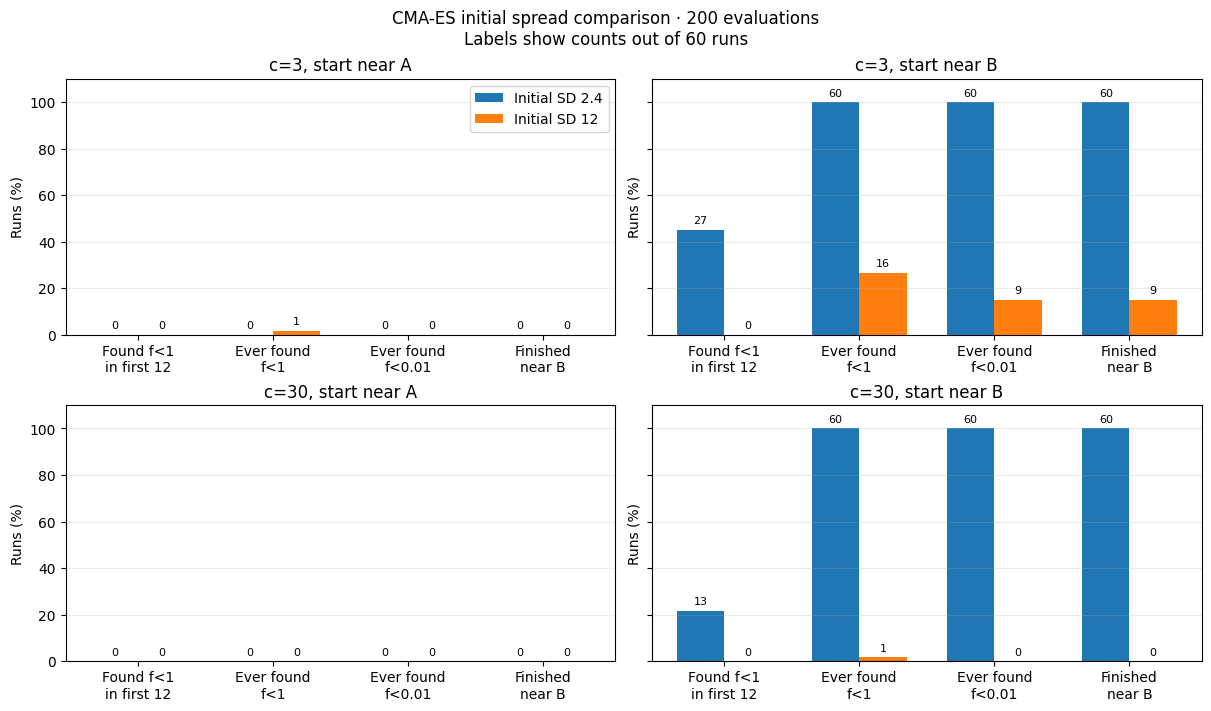

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
final = sigma_summary.loc[sigma_summary["evaluations"].eq(200)]
conditions = [(3, "a"), (3, "b"), (30, "a"), (30, "b")]
metrics = [
    ("first_generation_hits", "Found f<1\nin first 12"),
    ("discoveries", "Ever found\nf<1"),
    ("refinements", "Ever found\nf<0.01"),
    ("finished_near_b", "Finished\nnear B"),
]

fig, axes = plt.subplots(
    2, 2, figsize=(12, 7), sharey=True, layout="constrained"
)
positions = np.arange(len(metrics))
bar_width = 0.35

for ax, (c_value, basin) in zip(axes.flat, conditions):
    panel = final.loc[
        final["c"].eq(c_value) & final["start_basin"].eq(basin)
    ].set_index("initial_sd")

    for i, initial_sd in enumerate(initial_sds):
        row = panel.loc[initial_sd]
        counts = np.array([row[metric] for metric, _ in metrics], dtype=int)
        percentages = 100 * counts / row["runs"]

        bars = ax.bar(
            positions + (i - 0.5) * bar_width,
            percentages,
            width=bar_width,
            label=f"Initial SD {initial_sd:g}",
        )
        ax.bar_label(bars, labels=[str(count) for count in counts],
                     padding=3, fontsize=8)

    ax.set_xticks(positions, [label for _, label in metrics])
    ax.set(
        title=f"c={c_value}, start near {basin.upper()}",
        ylabel="Runs (%)",
        ylim=(0, 110),
    )
    ax.grid(axis="y", alpha=0.25)

axes[0, 0].legend()
fig.suptitle("CMA-ES initial spread comparison · 200 evaluations\n"
             "Labels show counts out of 60 runs")

output_dir = RESULTS_DIR

plot_path = output_dir / "cmaes_initial_spread_comparison.png"
zip_path = output_dir / "cmaes_initial_spread_results.zip"

fig.savefig(plot_path, dpi=200, bbox_inches="tight")
plt.show()

with ZipFile(zip_path, "w", compression=ZIP_DEFLATED) as archive:
    archive.write(plot_path, arcname=plot_path.name)
    archive.writestr("summary.csv", sigma_summary.to_csv(index=False))
    archive.writestr("checkpoint_results.csv", sigma_checkpoints.to_csv(index=False))
    archive.writestr("full_history.csv", sigma_history.to_csv(index=False))

print(f"Saved to {zip_path}")

## try slightly smaller domain

In [ ]:
LOWER = B2_SETTINGS["intermediate_domain"]["lower"]
UPPER = B2_SETTINGS["intermediate_domain"]["upper"]
WIDTH = UPPER - LOWER

A = np.asarray(B2_SETTINGS["intermediate_domain"]["a"])
B = np.asarray(B2_SETTINGS["intermediate_domain"]["b"])
R0 = B2_SETTINGS["intermediate_domain"]["r0"]

A_UNIT = (A - LOWER) / WIDTH
B_UNIT = (B - LOWER) / WIDTH

INITIAL_SD = B2_SETTINGS["intermediate_domain"]["initial_sd"]                  # Physical units. Set to 2.4 for a narrower start.
SIGMA0 = INITIAL_SD / WIDTH       # pycma uses normalised coordinates.
NEAR_B_CUTOFF = B2_SETTINGS["analysis"]["near_cutoff"] / WIDTH     # Same physical RMS cutoff as before.

C_VALUES = tuple(B2_SETTINGS["penalties"])
BUDGETS = tuple(B2_SETTINGS["budgets"])
SEEDS = B2_SETTINGS["seeds"]
START_FRACTIONS = tuple(B2_SETTINGS["start_fractions"])

LAMBDA_VALUES = tuple(B2_SETTINGS["population_sweep"])
MU_VALUES = tuple(B2_SETTINGS["parent_sweep"])
LAMBDA_CONFIGS = [(lam, lam // 2) for lam in LAMBDA_VALUES]
MU_CONFIGS = [(B2_SETTINGS["parent_sweep_population"], mu) for mu in MU_VALUES]
CONFIGS = list(dict.fromkeys(LAMBDA_CONFIGS + MU_CONFIGS))

STARTS = [
    (basin, fraction, centre + fraction * (other - centre))
    for basin, centre, other in (
        ("a", A_UNIT, B_UNIT),
        ("b", B_UNIT, A_UNIT),
    )
    for fraction in START_FRACTIONS
]




assert objective(A, 30) == 1.0
assert objective(B, 30) == 0.0

display(pd.DataFrame([
    {
        "start_basin": basin.upper(),
        "start_x": (LOWER + WIDTH * x0)[0],
        "start_y": (LOWER + WIDTH * x0)[1],
        "distance_from_starting_minimum": fraction * np.linalg.norm(B - A),
    }
    for basin, fraction, x0 in STARTS
]).round(3))

,start_basin,start_x,start_y,distance_from_starting_minimum
0,A,-4.5,0.0,0.5
1,A,-4.0,0.0,1.0
2,A,-3.5,0.0,1.5
3,B,4.5,0.0,0.5
4,B,4.0,0.0,1.0
5,B,3.5,0.0,1.5


In [ ]:
def make_strategy(x0, seed, lam, mu):
    es = cma.CMAEvolutionStrategy(
        x0.copy(),
        SIGMA0,
        {
            "bounds": [0.0, 1.0],
            "seed": int(seed),
            "popsize": lam,
            "CMA_mu": mu,
            "verbose": -9,
            "verb_log": 0,
        },
    )
    actual = (es.popsize, es.sp.weights.mu)
    if actual != (lam, mu):
        raise ValueError(f"Requested {(lam, mu)}, but pycma used {actual}")
    return es


def run_cma(c_value, basin, fraction, x0, seed, lam, mu):
    es = make_strategy(x0, seed, lam, mu)
    max_budget = max(BUDGETS)
    records = []

    evaluations = 0
    last_update = 0
    best_f = np.inf
    first_hit_eval = None
    first_hit_f = None
    first_hit_dist_b = None
    first_refined_eval = None

    def record_state():
        mean = np.asarray(es.mean)
        scaling = np.broadcast_to(np.asarray(es.sigma_vec.scaling), mean.shape)
        variance = es.sigma**2 * np.dot(np.diag(es.C), scaling**2)
        mean_dist_a = np.linalg.norm(mean - A_UNIT)
        mean_dist_b = np.linalg.norm(mean - B_UNIT)

        records.append({
            "c": c_value,
            "start_basin": basin,
            "start_fraction": fraction,
            "seed": seed,
            "popsize": lam,
            "mu": mu,
            "evaluations": evaluations,
            "last_update": last_update,
            "checkpoint": evaluations in BUDGETS,
            "D_a": np.sqrt(mean_dist_a**2 + variance),
            "D_b": np.sqrt(mean_dist_b**2 + variance),
            "spread": np.sqrt(variance),
            "best_f": best_f,
            "first_hit_eval": first_hit_eval,
            "first_hit_f": first_hit_f,
            "first_hit_dist_b": first_hit_dist_b,
            "first_refined_eval": first_refined_eval,
        })

    record_state()

    while evaluations < max_budget:
        candidates = es.ask()
        values = []

        for candidate in candidates:
            x = LOWER + WIDTH * np.asarray(candidate)
            value = objective(x, c_value)
            values.append(value)
            evaluations += 1
            best_f = min(best_f, value)

            if first_hit_eval is None and value < 1.0:
                first_hit_eval = evaluations
                first_hit_f = value
                first_hit_dist_b = float(np.linalg.norm(x - B))

            if first_refined_eval is None and value < 0.01:
                first_refined_eval = evaluations

            completed_generation = len(values) == len(candidates)
            if completed_generation:
                es.tell(candidates, values)
                last_update = evaluations

            if completed_generation or evaluations in BUDGETS:
                record_state()

            if evaluations == max_budget:
                break

    return records


# Check the effective population and parent counts before the full sweep.
for lam, mu in CONFIGS:
    make_strategy(STARTS[0][2], 1, lam, mu)

rows = []
for lam, mu in CONFIGS:
    for c_value, (basin, fraction, x0), seed in product(C_VALUES, STARTS, SEEDS):
        rows.extend(run_cma(c_value, basin, fraction, x0, seed, lam, mu))
    print(f"Finished λ={lam}, μ={mu}")

mid_history = pd.DataFrame(rows)
mid_checkpoints = mid_history.loc[mid_history["checkpoint"]].copy()

expected_runs = len(CONFIGS) * len(C_VALUES) * len(STARTS) * len(SEEDS)
assert len(mid_checkpoints) == expected_runs * len(BUDGETS)
print(f"Completed {expected_runs:,} runs")

Finished λ=6, μ=3
Finished λ=8, μ=4
Finished λ=12, μ=6
Finished λ=16, μ=8
Finished λ=24, μ=12
Finished λ=32, μ=16
Finished λ=48, μ=24
Finished λ=12, μ=2
Finished λ=12, μ=4
Finished λ=12, μ=8
Finished λ=12, μ=10
Completed 2,640 runs


,sweep,metric,c,start_basin,popsize,mu,discoveries,refinements,finished_near_b,runs
0,Population λ (μ = λ/2),refinements,3,a,8,4,7,1,1,60
1,Population λ (μ = λ/2),refinements,3,a,12,6,8,1,0,60
2,Population λ (μ = λ/2),refinements,3,a,16,8,8,1,0,60
3,Population λ (μ = λ/2),refinements,3,a,24,12,12,1,0,60
4,Population λ (μ = λ/2),refinements,3,a,32,16,13,1,0,60
5,Population λ (μ = λ/2),refinements,3,b,6,3,29,24,24,60
6,Population λ (μ = λ/2),refinements,30,a,32,16,4,2,0,60
7,Population λ (μ = λ/2),refinements,30,b,6,3,8,4,4,60
8,Population λ (μ = λ/2),refinements,30,b,48,24,34,4,0,60
9,Population λ (μ = λ/2),finished_near_b,3,a,8,4,7,1,1,60


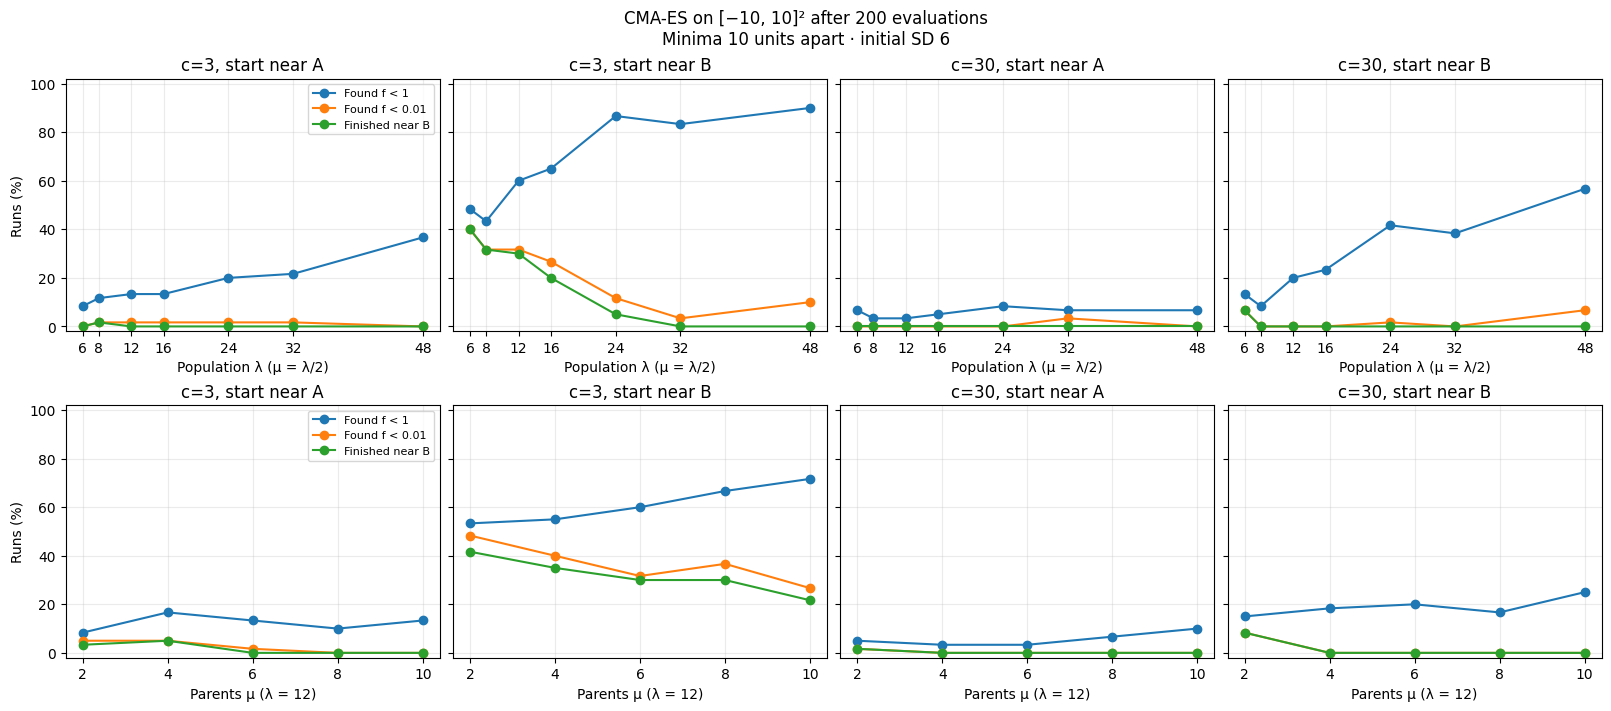

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
mid_checkpoints["discovered"] = mid_checkpoints["best_f"].lt(1.0)
mid_checkpoints["refined"] = mid_checkpoints["best_f"].lt(0.01)
mid_checkpoints["near_b"] = mid_checkpoints["D_b"].le(NEAR_B_CUTOFF)

mid_summary = (
    mid_checkpoints.groupby(
        ["c", "start_basin", "evaluations", "popsize", "mu"],
        as_index=False,
    )
    .agg(
        runs=("seed", "size"),
        discoveries=("discovered", "sum"),
        refinements=("refined", "sum"),
        finished_near_b=("near_b", "sum"),
        median_best_f=("best_f", "median"),
    )
)

for metric in ("discoveries", "refinements", "finished_near_b"):
    mid_summary[f"{metric}_pct"] = 100 * mid_summary[metric] / mid_summary["runs"]

plot_budget = 200
final = mid_summary.loc[mid_summary["evaluations"].eq(plot_budget)]

sweeps = [
    (
        final.loc[final["mu"].eq(final["popsize"] // 2)],
        "popsize", LAMBDA_VALUES, "Population λ (μ = λ/2)",
    ),
    (
        final.loc[final["popsize"].eq(12) & final["mu"].isin(MU_VALUES)],
        "mu", MU_VALUES, "Parents μ (λ = 12)",
    ),
]

best_rows = []
for table, _, _, label in sweeps:
    for metric in ("refinements", "finished_near_b"):
        peak = table.groupby(["c", "start_basin"])[metric].transform("max")
        best_rows.append(
            table.loc[table[metric].eq(peak)].assign(sweep=label, metric=metric)
        )

mid_best_settings = pd.concat(best_rows, ignore_index=True)
display(mid_best_settings[[
    "sweep", "metric", "c", "start_basin", "popsize", "mu",
    "discoveries", "refinements", "finished_near_b", "runs",
]])

conditions = [(3, "a"), (3, "b"), (30, "a"), (30, "b")]
metrics = [
    ("discoveries_pct", "Found f < 1", "tab:blue"),
    ("refinements_pct", "Found f < 0.01", "tab:orange"),
    ("finished_near_b_pct", "Finished near B", "tab:green"),
]

fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharey=True, layout="constrained")

for row, (table, x_key, ticks, xlabel) in enumerate(sweeps):
    for col, (c_value, basin) in enumerate(conditions):
        ax = axes[row, col]
        panel = table.loc[
            table["c"].eq(c_value) & table["start_basin"].eq(basin)
        ].sort_values(x_key)

        for metric, label, color in metrics:
            ax.plot(panel[x_key], panel[metric], marker="o", color=color, label=label)

        ax.set(
            title=f"c={c_value}, start near {basin.upper()}",
            xlabel=xlabel,
            xticks=ticks,
            ylim=(-2, 102),
        )
        ax.grid(alpha=0.25)
        if col == 0:
            ax.set_ylabel("Runs (%)")
            ax.legend(fontsize=8)

fig.suptitle(
    f"CMA-ES on [−10, 10]² after {plot_budget} evaluations\n"
    f"Minima 10 units apart · initial SD {INITIAL_SD:g}"
)

output_dir = RESULTS_DIR

stem = f"cmaes_domain_10_sd_{INITIAL_SD:g}"
plot_path = output_dir / f"{stem}.png"
zip_path = output_dir / f"{stem}.zip"

fig.savefig(plot_path, dpi=200, bbox_inches="tight")
plt.show()

with ZipFile(zip_path, "w", compression=ZIP_DEFLATED) as archive:
    archive.write(plot_path, arcname=plot_path.name)
    archive.writestr("summary.csv", mid_summary.to_csv(index=False))
    archive.writestr("best_settings.csv", mid_best_settings.to_csv(index=False))
    archive.writestr("checkpoint_results.csv", mid_checkpoints.to_csv(index=False))
    archive.writestr("full_history.csv", mid_history.to_csv(index=False))

print(f"Saved to {zip_path}")

## mean learning rate & Step-size adaptatio

In [ ]:
LOWER, UPPER = bounds[0]
WIDTH = UPPER - LOWER

A = BASIN_A.copy()
B = BASIN_B.copy()
R0 = CENTER_RADIUS

A_UNIT = (A - LOWER) / WIDTH
B_UNIT = (B - LOWER) / WIDTH

POP_SIZE, PARENT_COUNT = B2_SETTINGS["updates"]["popsize"], B2_SETTINGS["updates"]["mu"]
SIGMA0 = B2_SETTINGS["sigma0"]                        # Normalised. Initial physical SD = 2.4.
C_VALUES = tuple(B2_SETTINGS["penalties"])
BUDGETS = tuple(B2_SETTINGS["budgets"])
SEEDS = B2_SETTINGS["seeds"]
START_FRACTIONS = tuple(B2_SETTINGS["start_fractions"])
NEAR_CUTOFF = B2_SETTINGS["analysis"]["near_cutoff"]                    # Physical RMS distance, as before.

VARIANTS = B2_SETTINGS["updates"]["variants"]

STARTS = [
    (basin, fraction, centre + fraction * (other - centre))
    for basin, centre, other in (
        ("A", A_UNIT, B_UNIT),
        ("B", B_UNIT, A_UNIT),
    )
    for fraction in START_FRACTIONS
]




def run_update_test(c_value, basin, fraction, x0, seed, variant):
    options = VARIANTS[variant]
    es = cma.CMAEvolutionStrategy(
        x0.copy(),
        SIGMA0,
        {
            "bounds": [0.0, 1.0],
            "seed": seed,
            "popsize": POP_SIZE,
            "CMA_mu": PARENT_COUNT,
            "verbose": -9,
            "verb_log": 0,
            **options,
        },
    )
    assert (es.popsize, es.sp.weights.mu) == (POP_SIZE, PARENT_COUNT)

    run_id = {
        "c": c_value,
        "start_basin": basin,
        "start_fraction": fraction,
        "seed": seed,
        "variant": variant,
    }
    evaluations = 0
    best_f = np.inf
    first_hit = None
    first_refined = None
    first_hit_dist_b = np.nan
    mean_gain_on_hit_update = np.nan
    rows = []
    max_budget = max(BUDGETS)

    def state_metrics():
        mean = np.asarray(es.mean)
        scaling = np.broadcast_to(np.asarray(es.sigma_vec.scaling), mean.shape)
        variance = (WIDTH * es.sigma)**2 * np.dot(np.diag(es.C), scaling**2)
        dist_a = WIDTH * np.linalg.norm(mean - A_UNIT)
        dist_b = WIDTH * np.linalg.norm(mean - B_UNIT)

        return {
            "mean_dist_a": dist_a,
            "mean_dist_b": dist_b,
            "sigma": WIDTH * es.sigma,
            "spread": np.sqrt(variance),
            "D_a": np.sqrt(dist_a**2 + variance),
            "D_b": np.sqrt(dist_b**2 + variance),
        }

    state = state_metrics()

    while evaluations < max_budget:
        candidates = es.ask()
        values = []
        first_hit_this_generation = False

        for candidate in candidates:
            x = LOWER + WIDTH * np.asarray(candidate)
            value = float(objective(x, c_value))
            values.append(value)
            evaluations += 1
            best_f = min(best_f, value)

            if first_hit is None and value < 1.0:
                first_hit = evaluations
                first_hit_dist_b = np.linalg.norm(x - B)
                first_hit_this_generation = True

            if first_refined is None and value < 0.01:
                first_refined = evaluations

            if len(values) == len(candidates):
                previous_dist_b = state["mean_dist_b"]
                es.tell(candidates, values)
                state = state_metrics()

                if first_hit_this_generation:
                    mean_gain_on_hit_update = (
                        previous_dist_b - state["mean_dist_b"]
                    )

                if variant == "Fixed step size":
                    assert np.isclose(es.sigma, SIGMA0)

            rows.append({
                **run_id,
                "evaluations": evaluations,
                **state,
                "best_f": best_f,
                "first_hit": first_hit,
                "first_refined": first_refined,
                "first_hit_dist_b": first_hit_dist_b,
                "mean_gain_on_hit_update": mean_gain_on_hit_update,
            })

            if evaluations == max_budget:
                break

    return rows


rows = []
for variant in VARIANTS:
    for c_value, (basin, fraction, x0), seed in product(C_VALUES, STARTS, SEEDS):
        rows.extend(run_update_test(c_value, basin, fraction, x0, seed, variant))
    print(f"Finished {variant}")

history = pd.DataFrame(rows)
history["discovered"] = history["best_f"].lt(1.0)
history["refined"] = history["best_f"].lt(0.01)
history["near_a"] = history["D_a"].le(NEAR_CUTOFF)
history["near_b"] = history["D_b"].le(NEAR_CUTOFF)

checkpoints = history.loc[history["evaluations"].isin(BUDGETS)].copy()
summary = (
    checkpoints.groupby(["c", "start_basin", "evaluations", "variant"], sort=False)
    .agg(
        runs=("seed", "size"),
        discovered=("discovered", "sum"),
        refined=("refined", "sum"),
        near_a=("near_a", "sum"),
        near_b=("near_b", "sum"),
        median_best_f=("best_f", "median"),
        median_sigma=("sigma", "median"),
        median_spread=("spread", "median"),
        hits_with_completed_update=("mean_gain_on_hit_update", "count"),
        median_mean_gain_after_hit=("mean_gain_on_hit_update", "median"),
    )
    .reset_index()
)

assert summary["runs"].eq(len(SEEDS) * len(START_FRACTIONS)).all()
display(summary.round(5))

Finished Baseline
Finished Half mean step
Finished Fixed step size


,c,start_basin,evaluations,variant,runs,discovered,refined,near_a,near_b,median_best_f,median_sigma,median_spread,hits_with_completed_update,median_mean_gain_after_hit
0,3,A,50,Baseline,60,25,2,0,0,1.00692,1.33047,1.21170,25,1.27692
1,3,A,200,Baseline,60,27,21,36,18,1.00000,0.24463,0.02938,27,1.27692
2,3,B,50,Baseline,60,56,8,0,0,0.07924,1.32216,1.33418,56,-0.07039
3,3,B,200,Baseline,60,59,56,2,52,0.00002,0.19635,0.02364,59,-0.06863
4,30,A,50,Baseline,60,13,2,0,0,1.02840,1.29176,0.99506,13,1.18572
5,30,A,200,Baseline,60,13,5,53,4,1.00000,0.18381,0.01802,13,1.18572
6,30,B,50,Baseline,60,37,1,0,0,0.26938,2.45738,2.27524,37,-0.05638
7,30,B,200,Baseline,60,44,16,33,14,0.16827,0.48534,0.07632,44,-0.00789
8,3,A,50,Half mean step,60,28,1,0,0,1.00284,1.34818,1.25520,28,0.65134
9,3,A,200,Half mean step,60,30,13,42,10,0.77939,0.34012,0.03853,30,0.63863


,c,start_basin,metric,variant,variant_only,baseline_only
0,3,A,discovered,Half mean step,8,5
1,3,A,discovered,Fixed step size,18,3
2,3,A,refined,Half mean step,3,11
3,3,A,refined,Fixed step size,16,7
4,3,A,near_a,Half mean step,10,4
5,3,A,near_a,Fixed step size,4,18
6,3,A,near_b,Half mean step,3,11
7,3,A,near_b,Fixed step size,6,11
8,3,B,discovered,Half mean step,1,0
9,3,B,discovered,Fixed step size,1,0


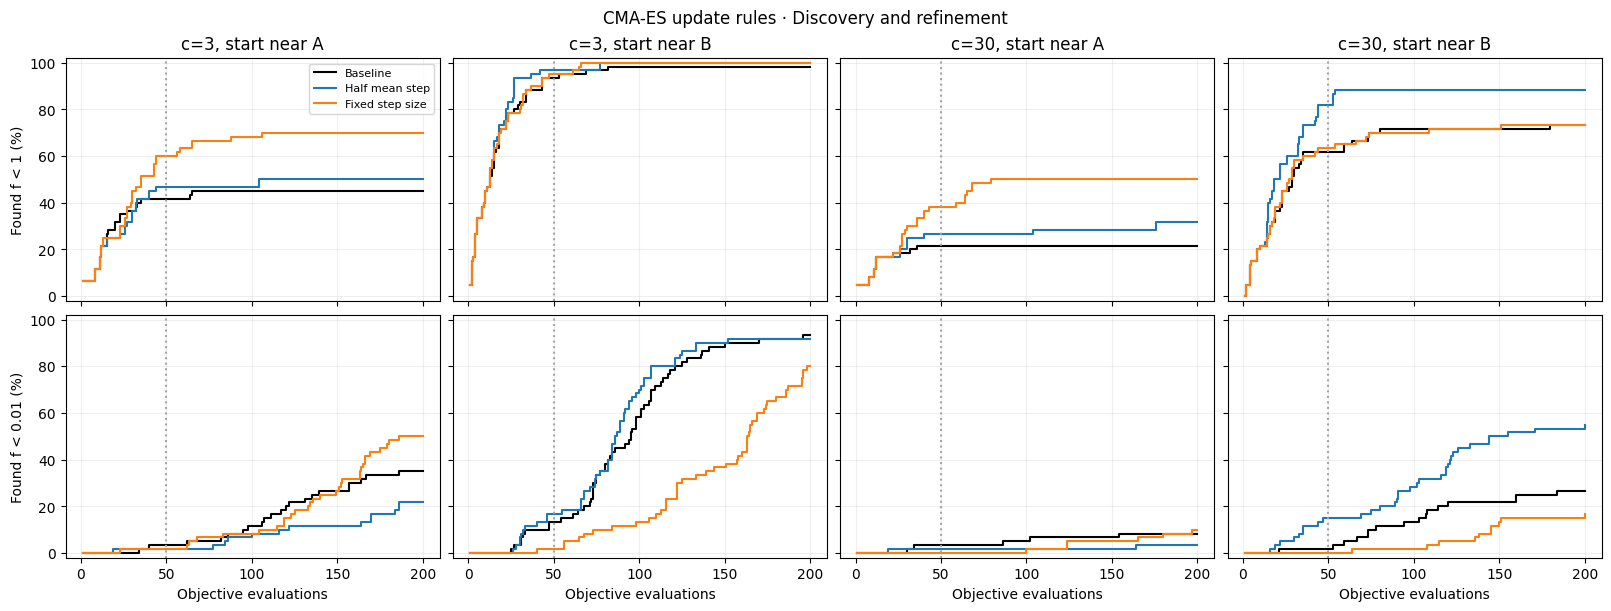

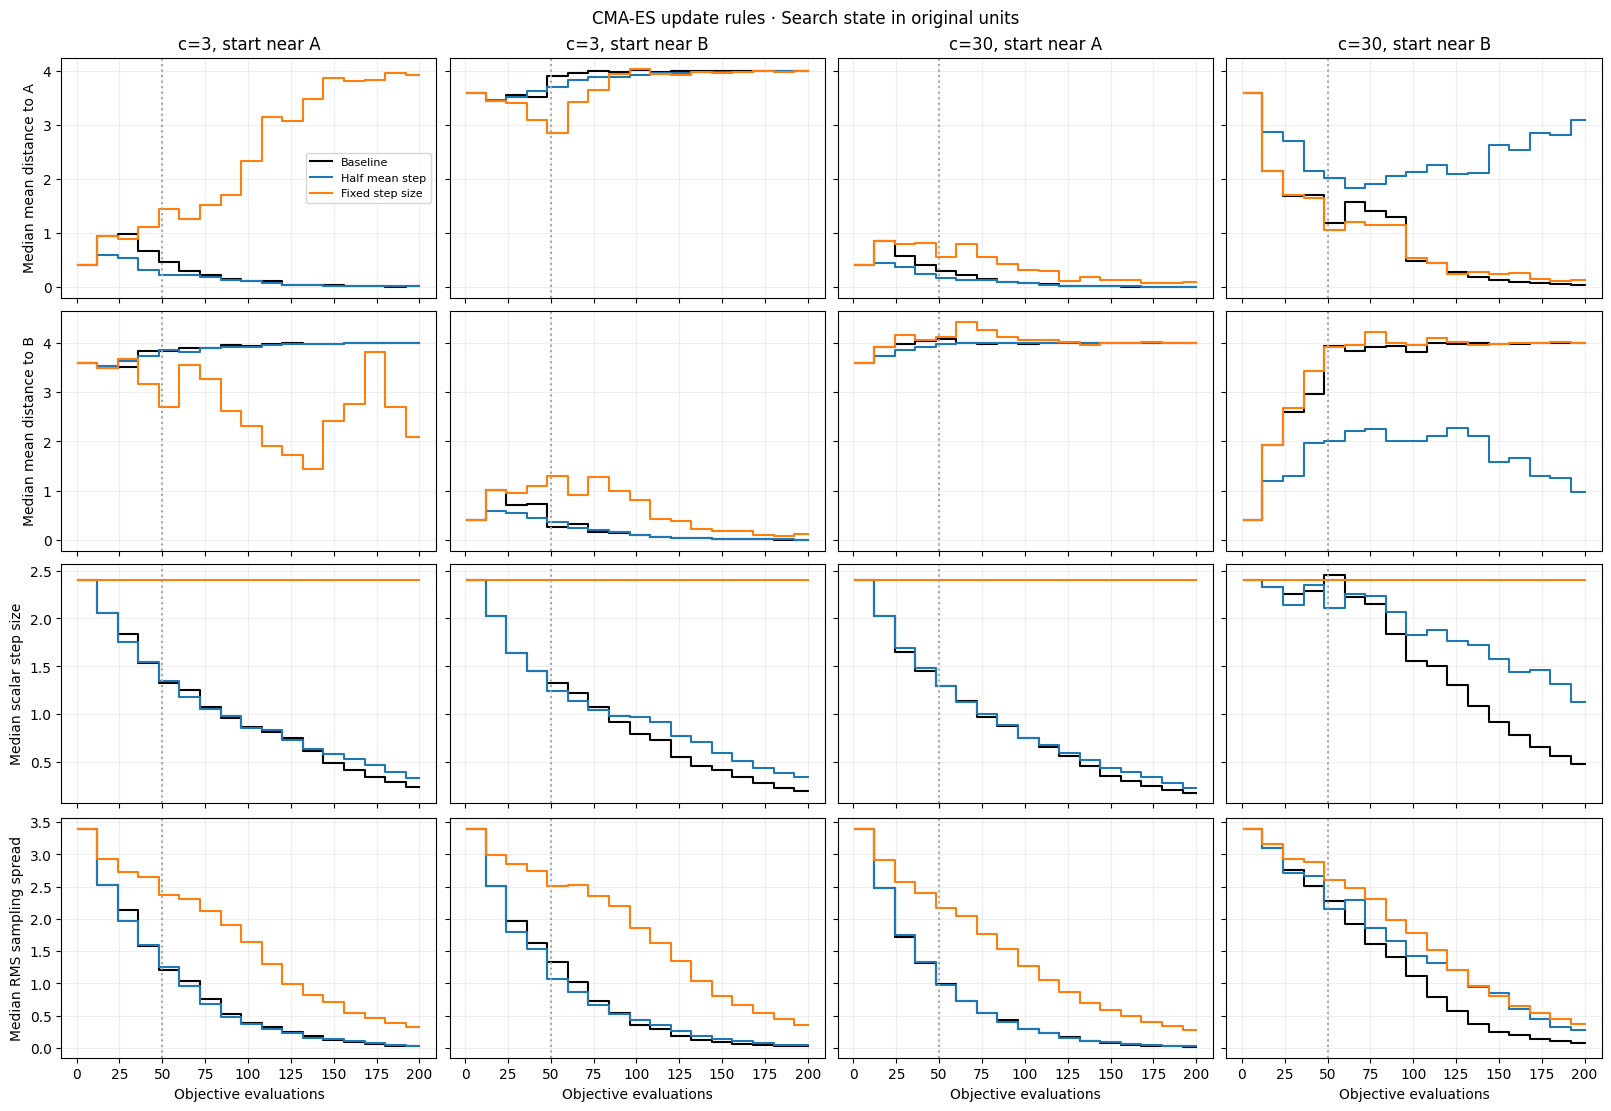

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
conditions = [(3, "A"), (3, "B"), (30, "A"), (30, "B")]
colors = {
    "Baseline": "black",
    "Half mean step": "tab:blue",
    "Fixed step size": "tab:orange",
}

curves = (
    history.groupby(["c", "start_basin", "variant", "evaluations"])
    .agg(
        discovery_rate=("discovered", "mean"),
        refinement_rate=("refined", "mean"),
        mean_dist_a=("mean_dist_a", "median"),
        mean_dist_b=("mean_dist_b", "median"),
        sigma=("sigma", "median"),
        spread=("spread", "median"),
    )
    .reset_index()
)

outcome_panels = [
    ("discovery_rate", "Found f < 1 (%)"),
    ("refinement_rate", "Found f < 0.01 (%)"),
]
state_panels = [
    ("mean_dist_a", "Median mean distance to A"),
    ("mean_dist_b", "Median mean distance to B"),
    ("sigma", "Median scalar step size"),
    ("spread", "Median RMS sampling spread"),
]


def plot_update_curves(metrics, title, percentages=False):
    fig, axes = plt.subplots(
        len(metrics), 4, figsize=(16, 2.5 * len(metrics) + 1),
        sharex=True, sharey="row", squeeze=False, layout="constrained",
    )

    for col, (c_value, basin) in enumerate(conditions):
        panel = curves.loc[
            curves["c"].eq(c_value) & curves["start_basin"].eq(basin)
        ]
        axes[0, col].set_title(f"c={c_value}, start near {basin}")

        for row, (metric, ylabel) in enumerate(metrics):
            ax = axes[row, col]

            for variant, color in colors.items():
                run_curve = panel.loc[panel["variant"].eq(variant)]
                values = run_curve[metric] * (100 if percentages else 1)
                ax.step(
                    run_curve["evaluations"], values,
                    where="post", color=color, label=variant,
                )

            ax.axvline(50, color="0.65", linestyle=":")
            ax.grid(alpha=0.2)
            if percentages:
                ax.set_ylim(-2, 102)
            if col == 0:
                ax.set_ylabel(ylabel)
            if row == len(metrics) - 1:
                ax.set_xlabel("Objective evaluations")

    axes[0, 0].legend(fontsize=8)
    fig.suptitle(title)
    return fig


outcome_fig = plot_update_curves(
    outcome_panels, "CMA-ES update rules · Discovery and refinement", True
)
state_fig = plot_update_curves(
    state_panels, "CMA-ES update rules · Search state in original units"
)

# Count wins and losses on the same start and seed against the baseline.
final = checkpoints.loc[checkpoints["evaluations"].eq(200)]
paired_rows = []

for (c_value, basin), group in final.groupby(["c", "start_basin"]):
    for metric in ("discovered", "refined", "near_a", "near_b"):
        paired = group.pivot(
            index=["start_fraction", "seed"], columns="variant", values=metric
        )
        for variant in ("Half mean step", "Fixed step size"):
            baseline, changed = paired["Baseline"], paired[variant]
            paired_rows.append({
                "c": c_value,
                "start_basin": basin,
                "metric": metric,
                "variant": variant,
                "variant_only": int((changed & ~baseline).sum()),
                "baseline_only": int((baseline & ~changed).sum()),
            })

paired_comparison = pd.DataFrame(paired_rows)
display(paired_comparison)

output_dir = RESULTS_DIR

outcome_path = output_dir / "cmaes_update_outcomes.png"
state_path = output_dir / "cmaes_update_search_state.png"
zip_path = output_dir / "cmaes_update_rule_results.zip"

outcome_fig.savefig(outcome_path, dpi=200, bbox_inches="tight")
state_fig.savefig(state_path, dpi=200, bbox_inches="tight")
plt.show()

with ZipFile(zip_path, "w", compression=ZIP_DEFLATED) as archive:
    for path in (outcome_path, state_path):
        archive.write(path, arcname=path.name)
    archive.writestr("summary.csv", summary.to_csv(index=False))
    archive.writestr("paired_comparison.csv", paired_comparison.to_csv(index=False))
    archive.writestr("checkpoint_results.csv", checkpoints.to_csv(index=False))
    archive.writestr("full_history.csv", history.to_csv(index=False))

print(f"Saved to {zip_path}")

In [ ]:
EXPORTS = {
    "01_population_and_parent_count": "cmaes_lambda_mu_results.zip",
    "02_convergence_sweeps": "cmaes_convergence_sweeps.zip",
    "03_wide_domain": "cmaes_wide_domain_farther_basins.zip",
    "04_initial_spread": "cmaes_initial_spread_results.zip",
    "05_intermediate_domain": f"cmaes_domain_10_sd_{INITIAL_SD:g}.zip",
    "06_mean_and_step_size_updates": "cmaes_update_rule_results.zip",
}

# Set this to the folder containing the exports if you uploaded them elsewhere.
source_dir = RESULTS_DIR
export_paths = {
    label: source_dir / filename for label, filename in EXPORTS.items()
}

missing = [path.name for path in export_paths.values() if not path.is_file()]
if missing:
    raise FileNotFoundError(
        "Upload these exports into the Colab Files sidebar, or correct "
        "their names in EXPORTS:\n" + "\n".join(missing)
    )

invalid = [path.name for path in export_paths.values() if not is_zipfile(path)]
if invalid:
    raise ValueError("Invalid ZIP exports:\n" + "\n".join(invalid))

readme = dedent("""
    # CMA-ES on a two-basin objective

    We investigated when CMA-ES discovers a better basin and when it
    converts that discovery into a precise solution under a fixed budget.

    ## How to read the results

    - Discovery means at least one evaluated point had f < 1.
    - Precision means at least one evaluated point had f < 0.01.
    - Finishing near B means the final sampling distribution was centred
      and concentrated near B according to the experiment's D_b cutoff.

    ## Experiments and findings

    1. Population and parent count. The factorial comparison varied
       lambda and mu separately. Doubling lambda improved discovery
       and final concentration near B in the tested comparisons with
       mu fixed. Increasing mu had a more mixed effect.

    2. Convergence sweeps. With mu = lambda/2, larger populations
       generally improved discovery under 200 evaluations. Very large
       populations often refined less successfully. For c = 30 and
       starts near B, lambda 16 to 48 increased discovery from 46/60
       to 59/60, while precision fell from 22/60 to 12/60.

    3. Wide domain. With the box widened to [-20, 20]^2 and the minima
       farther apart, discovery from near A became rare, especially
       at c = 30. The box, separation, starting offsets and physical
       initial spread changed together.

    4. Initial spread. In the wide domain with starts close to B,
       physical initial SD 2.4 reached f < 0.01 in 60/60 runs at
       c = 30, versus 0/60 with SD 12. From near A, both spreads
       rarely found B.

    5. Intermediate domain. The [-10, 10]^2 sweep repeats the
       population and parent-count comparisons at intermediate basin
       separation. See the exported summary and plots for its results.

    6. Update rules. At fixed lambda = 12 and mu = 6, holding the
       step size fixed improved discovery from near A at c = 30
       (30/60 versus 13/60), with little gain in precision
       (6/60 versus 5/60). Halving the mean update improved precision
       from near B at c = 30 (33/60 versus 16/60).

    ## Scope

    These results describe the tested landscape, starts and evaluation
    budgets. The settings that helped discovery and those that helped
    refinement depended on the starting location and landscape.
""").strip() + "\n"

bundle = RESULTS_DIR / "cmaes_two_basin_experiments.zip"

with ZipFile(bundle, "w", compression=ZIP_DEFLATED) as archive:
    archive.writestr("README.md", readme)
    for label, path in export_paths.items():
        archive.write(path, arcname=f"experiments/{label}/{path.name}")

with ZipFile(bundle) as archive:
    if archive.testzip() is not None:
        raise ValueError("Bundle integrity check failed.")
    print("\n".join(archive.namelist()))



README.md
experiments/01_population_and_parent_count/cmaes_lambda_mu_results.zip
experiments/02_convergence_sweeps/cmaes_convergence_sweeps.zip
experiments/03_wide_domain/cmaes_wide_domain_farther_basins.zip
experiments/04_initial_spread/cmaes_initial_spread_results.zip
experiments/05_intermediate_domain/cmaes_domain_10_sd_6.zip
experiments/06_mean_and_step_size_updates/cmaes_update_rule_results.zip
Saved all results: https://github.com/bbny27/DSA4212-G1/blob/beckham/experiment-1/results/cmaes_two_basin_experiments.zip
